### Quick look at results

In [53]:
import numpy as np
from matplotlib.patches import Rectangle
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib import colormaps
import matplotlib.pyplot as plt

from pycirclize import Circos
import reframed
import pandas as pd
from collections import OrderedDict
from os import listdir


In [54]:

def clean_met_name(met):
    replacements = {
        "_e": "__91__e__93__",
        "__D": "_D",
        "__L": "_L",
        "__R": "_R"
    }
    for old, new in replacements.items():
        met = met.replace(old, new)
    return met
met2superclass_dict = pd.read_csv("../../../GEMs_from_MAGs/output/met_chebi_class.tsv",sep="\t",index_col=0)["self defined super class"].to_dict()
met2superclass_dict = {clean_met_name(met):s_class for met,s_class in met2superclass_dict.items()} 


from molmass import Formula
import pandas as pd
import reframed
import numpy as np
import sys


def assign_super_class(x):
    super_class = "other"
    if x in met2superclass_dict.keys():
        super_class = met2superclass_dict[x]
    return super_class   


def preprocessing_func(steadiercom_samples):
    
    steadiercom_samples_preprocessed = steadiercom_samples.copy()
    steadiercom_samples_preprocessed["mass_rate*frequency"] = steadiercom_samples_preprocessed.apply(lambda row: row.mass_rate*row.frequency,axis=1)
    steadiercom_samples_preprocessed["super_class"] = steadiercom_samples_preprocessed.compound.map(assign_super_class)
    
    # Only relevant compounds will be classified, rest is "other"
    #steadiercom_samples_preprocessed["super_class"] = steadiercom_samples_preprocessed["super_class"].map(lambda x: x if x in met2superclass_dict.keys() else "other")
    
    return steadiercom_samples_preprocessed


def data_ReceiverOrDonor(steadiercom_samples_preprocessed,ReceiverOrDonor,only_media=False):
    """
    ReceiverOrDonor (string): Either 'receiver' or 'donor'
    """
    steadiercom_only_producers = steadiercom_samples_preprocessed[(steadiercom_samples_preprocessed.donor!="environment")]
    steadiercom_only_consumers = steadiercom_samples_preprocessed[(steadiercom_samples_preprocessed.receiver!="environment")]
    
    members =  set(list(steadiercom_only_producers.donor.unique())+list(steadiercom_only_consumers.receiver.unique()))
    
    if only_media:
        if ReceiverOrDonor=="receiver":
            steadiercom_crossfeeding_from_media = steadiercom_samples_preprocessed[steadiercom_samples_preprocessed.donor=="environment"].copy()
        elif ReceiverOrDonor=="donor":
            steadiercom_crossfeeding_from_media = steadiercom_samples_preprocessed[steadiercom_samples_preprocessed.receiver=="environment"].copy()
    else:
        steadiercom_crossfeeding_from_media = steadiercom_samples_preprocessed.copy()
    
    
    # For each receiver/super_class couple -> sum across axis
    data_receiverOrdonor_df = steadiercom_crossfeeding_from_media.groupby(["super_class",ReceiverOrDonor]).sum()["mass_rate*frequency"].unstack().fillna(0)
    if "environment" in columns:
        data_receiverOrdonor_df = data_receiverOrdonor_df.drop("environment",axis=1)
    
    ## Add data for missing members:
    missing_members = set(members)-set(data_receiverOrdonor_df.columns)
    for member in missing_members:
        receiver_or_donor = member
        
        data_receiverOrdonor_df[receiver_or_donor]=np.zeros(len(data_receiverOrdonor_df.index))
    
    return data_receiverOrdonor_df




def data_for_links(steadiercom_crossfeeding_only,members,min_flux=0):

    links = []
    
    member_range = {member:{"upper_donor":[],"upper_receiver":[]} for member in members}

    sum_fluxes = steadiercom_crossfeeding_only[steadiercom_crossfeeding_only["mass_rate*frequency"]>min_flux]["mass_rate*frequency"].sum()
    
    for index,row in steadiercom_crossfeeding_only.iterrows():
        link = []

        # Donor
        donor =row.donor

        # Receiver
        receiver =row.receiver

        flux_g = row["mass_rate*frequency"]

        
        if flux_g<min_flux:
            continue

        lower_receiver_i = 0 if len(member_range[receiver]["upper_receiver"]) == 0 else member_range[receiver]["upper_receiver"][-1]
        upper_receiver_i = lower_receiver_i + flux_g/sum_fluxes
        
        lower_donor_i = 0 if len(member_range[donor]["upper_donor"]) == 0 else member_range[donor]["upper_donor"][-1]
        upper_donor_i = lower_donor_i + flux_g/sum_fluxes
        

        member_range[receiver]["upper_receiver"].append(upper_receiver_i)

        member_range[donor]["upper_donor"].append(upper_donor_i)
        
        link.append((donor,1-lower_donor_i,1-upper_donor_i))   
        link.append((receiver,lower_receiver_i,upper_receiver_i))
     

        link.append(row.super_class)
        links.append(link)
        
        
    return links


def circos_plot_process_data(steadiercom_samples,community_id=False,min_flux=0,compound_type=False,min_frequency=0):
    
    
    # Add super_class and mass_rate*frequency
    steadiercom_samples_preprocessed = preprocessing_func(steadiercom_samples)
    
    #return steadiercom_samples_preprocessed
    # Select data for community
    if community_id:
        steadiercom_samples_preprocessed_copy = steadiercom_samples_preprocessed[steadiercom_samples_preprocessed.community==community_id].copy()
    else:
        steadiercom_samples_preprocessed_copy = steadiercom_samples_preprocessed.copy()
    
    # find members
    steadiercom_crossfeeding_only_producers = steadiercom_samples_preprocessed_copy[(steadiercom_samples_preprocessed_copy.donor!="environment")]
    steadiercom_crossfeeding_only_consumers = steadiercom_samples_preprocessed_copy[(steadiercom_samples_preprocessed_copy.receiver!="environment")]
    members =  set(list(steadiercom_crossfeeding_only_producers.donor.unique())+list(steadiercom_crossfeeding_only_consumers.receiver.unique()))
    
    # sort the members according to coverage
    #members = steadiercom_samples.donors.unique()
    
    
    # remove all data related to environment
    steadiercom_samples_preprocessed_copy = steadiercom_samples_preprocessed_copy[(steadiercom_samples_preprocessed_copy.donor!="environment") & (steadiercom_samples_preprocessed_copy.receiver!="environment")]
    
    # filter out lower frequencies 
    steadiercom_samples_preprocessed_copy = steadiercom_samples_preprocessed_copy[steadiercom_samples_preprocessed_copy.frequency>min_frequency].copy()
    
    ## Production data (add superclass and convert to mass_rate)
    if compound_type:
        mets_interesting = chebi_interesting[chebi_interesting["self defined super class"].isin(compound_type)].index.values
        steadiercom_crossfeeding = steadiercom_samples_preprocessed_copy[steadiercom_samples_preprocessed_copy.compound.isin(mets_interesting)].copy()
    else:
        steadiercom_crossfeeding = steadiercom_samples_preprocessed_copy.copy()
    steadiercom_crossfeeding = steadiercom_crossfeeding.groupby(["donor","receiver","super_class"]).sum()["mass_rate*frequency"].reset_index()
    # Sort crossfeeding data according to the 
    steadiercom_crossfeeding.donor = steadiercom_crossfeeding.donor.astype("category")
    steadiercom_crossfeeding.donor = steadiercom_crossfeeding.donor.cat.set_categories(members)
    steadiercom_crossfeeding.receiver = steadiercom_crossfeeding.receiver.astype("category")
    steadiercom_crossfeeding.receiver = steadiercom_crossfeeding.receiver.cat.set_categories(members)
    steadiercom_crossfeeding = steadiercom_crossfeeding.sort_values(["donor","receiver"],ascending=[False,True]).copy()
    

    links = data_for_links(steadiercom_crossfeeding,members,min_flux=min_flux)
    super_classes = steadiercom_samples_preprocessed.super_class.unique()
    
    return links,members,super_classes


def plot_circos_plot(links,members,super_classes,member_lut,superclass_lut,fontsize=22,title=None,extra_compounds=False,move_legend=0):
    ### Plot
    #color_dict = chebi_lut

    sectors = {member:1 for member in members}
    circos = Circos(sectors,space=5)
    
    
    
    # Find colors for genus 
    #genera,genus_groups,mag2genus_dict,genus2color_dict = get_genus_colors(members)
    
    # Find colors for genus 
    
    i = 0
    
    index_color = np.arange(0.1,1.0,0.9/len(circos.sectors))
    
    genera_specific = []
    
    for sector in circos.sectors:
        
        # Add color for group
        track = sector.add_track((95, 100))
        
        #track.axis(fc=genus2color_dict[mag2genus_dict[sector.name]])
        track.axis(fc=member_lut[sector.name])
        
        genera_specific.append(sector.name)
        i+=1

    classes = []
    for link in links:

        if link[2]!= "other":
            #color = chebi_interesting[chebi_interesting["self defined super class"]==link[2]].iloc[0,-1]
            color = superclass_lut[link[2]]
            class_ = link[2]
        else:
            color = "#eaeaea"

            class_ = "other" 
            superclass_lut[class_]=color
            

        circos.link(link[0],link[1],direction=1,color=color,ec=color,arrow_length_ratio=0.15,allow_twist=False)

        classes.append(class_)
        
     ### Plot

    fig = circos.plotfig()
    
    if extra_compounds:
        classes.extend(extra_compounds)
        
    classes = sorted(list(set(classes)))
        
    colors_classes =[(superclass_lut[class_], class_) for class_ in classes]
    
    line_handles = [Patch(color=color_code[0], label=color_code[1],alpha=0.8) for color_code in colors_classes]
    line_legend = circos.ax.legend(
        handles=line_handles,
        #bbox_to_anchor=(1.0, 1.35+move_legend),  # Positioning to the right of the plot
        #loc='upper left', 
        #fontsize=fontsize,
        title="Compound",
        #handlelength=2,
    )
    
    line_legend.get_title().set_fontsize(str(fontsize))
    line_legend._legend_box.align = "left"
        
    
    # Legend for genus

    genus_handles = [Patch(color=member_lut[genus], label=genus) for genus in genera_specific]
    
    genus_legend = circos.ax.legend(
        handles=genus_handles,
        #bbox_to_anchor=(1,0.5+move_legend),  # Positioning to the lower right
        loc='upper right',
        #fontsize=fontsize,
        title="Genus",
        #handlelength=2,
    )
    
    genus_legend.get_title().set_fontsize(str(fontsize))
    genus_legend._legend_box.align = "left"
    
    circos.ax.add_artist(line_legend)
    circos.ax.add_artist(genus_legend)

    mag2color= dict(zip(members,index_color))
    #plt.close()
    return fig,mag2color,line_legend,genus_legend



def data_ReceiverOrDonor(steadiercom_samples_preprocessed,ReceiverOrDonor,only_media=False):
    """
    ReceiverOrDonor (string): Either 'receiver' or 'donor'
    """
    steadiercom_only_producers = steadiercom_samples_preprocessed[(steadiercom_samples_preprocessed.donor!="environment")]
    steadiercom_only_consumers = steadiercom_samples_preprocessed[(steadiercom_samples_preprocessed.receiver!="environment")]
    
    members =  set(list(steadiercom_only_producers.donor.unique())+list(steadiercom_only_consumers.receiver.unique()))
    
    if only_media:
        if ReceiverOrDonor=="receiver":
            steadiercom_crossfeeding_from_media = steadiercom_samples_preprocessed[steadiercom_samples_preprocessed.donor=="environment"].copy()
        elif ReceiverOrDonor=="donor":
            steadiercom_crossfeeding_from_media = steadiercom_samples_preprocessed[steadiercom_samples_preprocessed.receiver=="environment"].copy()
    else:
        steadiercom_crossfeeding_from_media = steadiercom_samples_preprocessed.copy()
    
    
    # For each receiver/super_class couple -> sum across axis
    data_receiverOrdonor_df = steadiercom_crossfeeding_from_media.groupby(["super_class",ReceiverOrDonor]).sum()["mass_rate*frequency"].unstack().fillna(0)
    
    if "environment" in data_receiverOrdonor_df.columns:
        data_receiverOrdonor_df = data_receiverOrdonor_df.drop("environment",axis=1)
    
    ## Add data for missing members:
    missing_members = set(members)-set(data_receiverOrdonor_df.columns)
    for member in missing_members:
        receiver_or_donor = member
        
        data_receiverOrdonor_df[receiver_or_donor]=np.zeros(len(data_receiverOrdonor_df.index))
    
    return data_receiverOrdonor_df


def data_uptake_prod(steadiercom_samples,community_id=False,compound_type=False,only_media=False,min_frequency=0.0):
    
    
    steadiercom_samples_preprocessed = preprocessing_func(steadiercom_samples)
    
    
    
    # filter out lower frequencies 
    steadiercom_samples_preprocessed = steadiercom_samples_preprocessed[steadiercom_samples_preprocessed.frequency>min_frequency].copy()
    
    
    ## Process input data (add superclass and convert to mass_rate)
    
    if community_id:
        
        steadiercom_samples_preprocessed_copy = steadiercom_samples_preprocessed[steadiercom_samples_preprocessed.community==community_id].copy()
        
    else:
        steadiercom_samples_preprocessed_copy = steadiercom_samples_preprocessed.copy()

        
    if compound_type:
        steadiercom_samples_preprocessed_copy.loc[:,"mass_rate*frequency"] = steadiercom_samples_preprocessed_copy.apply(lambda x: 0 if x.super_class not in compound_type else x["mass_rate*frequency"],axis=1)

    
    # DATA CONSUMERS

    data_receiver_df = data_ReceiverOrDonor(steadiercom_samples_preprocessed_copy,"receiver",only_media=only_media)
    # DATA PRODUCERS
    data_donor_df = data_ReceiverOrDonor(steadiercom_samples_preprocessed_copy,"donor",only_media=only_media)
    
    # DATA FOR ABUNDANCE "PLOT  
    ## Sort dataframes
    data_receiver_df = data_receiver_df.sort_index().copy()
    
    data_donor_df = data_donor_df.loc[:,data_receiver_df.columns].copy()
    data_donor_df = data_donor_df.sort_index().copy()
    
    return data_receiver_df,data_donor_df#,community_abundance


def plot_uptake_prod(data_receiver_df,data_donor_df,members_lut,super_class_lut,title=None,legend=True):
    members = list(data_donor_df.columns)+list(data_receiver_df.columns)
    
    # Find colors for genus 
    
    fig, axs = plt.subplots(3,gridspec_kw={'height_ratios': [3,0.5,3]},figsize=(20,15),sharex=True)

    # Relative abundance


    # Producing bars
    data_donor_df = data_donor_df.loc[data_donor_df.sum(axis=1)>1e-20,:].copy()
    data_donor_df.transpose().plot(kind="bar",ax=axs[0],color=super_class_lut,legend=None,stacked=True,alpha=0.8)
    axs[0].set_xticks([])
    axs[0].tick_params(labelsize=25)
    axs[0].set_xlabel('')
    axs[0].set_title("Production \n [mg/h/g$_{bio}$)]",x=-.1,y=0.2,fontsize=30,rotation=90)

    # Genus colors
    xticks_labels = data_receiver_df.columns
    xticks = np.arange(0,len(xticks_labels))
    index_color = np.arange(0.1,1.0,0.9/len(xticks_labels))
    
    axs[1].set_yticks([])
    axs[1].set_xticks(xticks)
    
    genera_specific = []

    for i,x in enumerate(xticks_labels):
        patch=Rectangle((i-0.5, 0),1, 1, color=members_lut[x])
        genera_specific.append(x)
        
        axs[1].add_patch(patch)

    axs[1].set_xticks([])


    plt.subplots_adjust(left=0.1,
                        bottom=0.1, 
                        right=0.9, 
                        top=0.9, 
                        wspace=0.1, 
                        hspace=0.05)
                        

    #plt.subplots_adjust(left=0, bottom=0, right=1, top=1, wspace=0, hspace=0)

    axs[1].set_xticks([])

    # Consuming bars
    data_receiver_df = data_receiver_df.loc[data_receiver_df.sum(axis=1)>1e-20,:].copy()
    data_receiver_df.transpose().apply(lambda x: (-1)*x).plot(kind="bar",ax=axs[2],color=super_class_lut,legend=None,stacked=True,alpha=0.8)
    axs[2].set_xticks([])
    axs[2].tick_params(labelsize=25)
    axs[2].set_xlabel('')
    axs[2].set_title("Consumption \n [mg/h/g$_{bio}$)]",x=-.1,y=0.2,fontsize=30,rotation=90)
    mag2color= dict(zip(xticks_labels,index_color))
    if legend:    
        # Custom legend for compounds
        custom_lines = [Patch(color=super_classes_lut[super_class], label=super_class,alpha=0.8) for super_class in  pd.concat([data_donor_df,data_receiver_df]).index.unique()]
        
        fig.legend(custom_lines,pd.concat([data_donor_df,data_receiver_df]).index.unique(), fontsize=19, loc='upper left', bbox_to_anchor=(0.9, 1.0), title="COMPOUNDS")

        # Custom legend for genera (example, replace with your actual genus data)  
        genus_labels = genera_specific
        
        genus_handles = [Patch(color=members_lut[genus], label=genus) for genus in genus_labels] 
        
        genus_legend = fig.legend(genus_handles, genus_labels, fontsize=19, loc='upper left', bbox_to_anchor=(0.9, 0.5), title="GENUS")    
        
        fig.suptitle(title,fontsize=30)
        #plt.close()
    else:
        
        extra_compounds = list(pd.concat([data_donor_df,data_receiver_df]).index.unique())
        plt.close()
        return fig, mag2color,extra_compounds
    
    
    return fig, mag2color



In [55]:
dfs = []
for file in listdir("../output/Venturelli2018/results_steadiercom/results_growth_test/"):
    if file.endswith(".tsv") and (not file.endswith("abundance.tsv")):
        df = pd.read_csv("../output/Venturelli2018/results_steadiercom/results_growth_test/"+file,sep="\t")
        dfs.append(df)
steadiercom_growth = pd.concat(dfs)

In [56]:
links,members,super_classes = circos_plot_process_data(steadiercom_growth,min_flux=0,compound_type=False,min_frequency=0.000) 
colormap = plt.get_cmap("tab20")

super_classes_lut = dict(zip(super_classes,colormap(np.linspace(0,1,len(super_classes)))))


colormap = plt.get_cmap("turbo")

members_lut = dict(zip(members,colormap(np.linspace(0,1,len(members)))))

In [57]:
steadiercom_growth.query("donor!='environment' & receiver!='environment'").sort_values("frequency",ascending=False)

,donor,receiver,compound,mass_rate,rate,frequency,community,medium
388,Faecalibacterium_prausnitzii_A2_165,Clostridium_hiranonis_TO_931_DSM_13275,M_thymd__91__e__93__,1.028752e-04,4.247040e-04,0.050000,CA-,LB_extend
317,Eubacterium_rectale_ATCC_33656,Collinsella_aerofaciens_ATCC_25986,M_acald__91__e__93__,3.502201e-04,7.950080e-03,0.040000,FP-,LB_extend
423,Faecalibacterium_prausnitzii_A2_165,Clostridium_hiranonis_TO_931_DSM_13275,M_thymd__91__e__93__,5.007299e-05,2.067184e-04,0.040000,NONE,LB_extend
139,Collinsella_aerofaciens_ATCC_25986,Eggerthella_lenta_DSM_2243,M_orn__91__e__93__,1.031937e-02,7.749113e-02,0.030000,PC-,LB_extend
378,Faecalibacterium_prausnitzii_A2_165,Eggerthella_lenta_DSM_2243,M_nh4__91__e__93__,2.069898e-04,1.147501e-02,0.030000,NONE,LB_extend
...,...,...,...,...,...,...,...,...
652,Eubacterium_rectale_ATCC_33656,Prevotella_copri_CB7_DSM_18205,M_glu_L__91__e__93__,1.987746e-06,1.360342e-05,0.000667,BH-,LB_extend
653,Bacteroides_ovatus_ATCC_8483,Bacteroides_uniformis_ATCC_8492,M_gsn__91__e__93__,7.113877e-07,2.511606e-06,0.000667,BH-,LB_extend
654,Clostridium_hiranonis_TO_931_DSM_13275,Eubacterium_rectale_ATCC_33656,M_nh4__91__e__93__,6.428553e-07,3.563835e-05,0.000667,BH-,LB_extend
656,Eubacterium_rectale_ATCC_33656,Clostridium_hiranonis_TO_931_DSM_13275,M_cys_L__91__e__93__,3.458650e-07,2.854664e-06,0.000667,BH-,LB_extend


(<Figure size 2000x1500 with 3 Axes>,
 {'Bacteroides_ovatus_ATCC_8483': np.float64(0.1),
  'Bacteroides_thetaiotaomicron_VPI_5482': np.float64(0.175),
  'Bacteroides_uniformis_ATCC_8492': np.float64(0.24999999999999997),
  'Bacteroides_vulgatus_ATCC_8482': np.float64(0.32499999999999996),
  'Blautia_hydrogenotrophica_DSM_10507': np.float64(0.3999999999999999),
  'Clostridium_hiranonis_TO_931_DSM_13275': np.float64(0.47499999999999987),
  'Collinsella_aerofaciens_ATCC_25986': np.float64(0.5499999999999999),
  'Desulfovibrio_piger_ATCC_29098': np.float64(0.6249999999999999),
  'Eggerthella_lenta_DSM_2243': np.float64(0.6999999999999998),
  'Eubacterium_rectale_ATCC_33656': np.float64(0.7749999999999998),
  'Faecalibacterium_prausnitzii_A2_165': np.float64(0.8499999999999998),
  'Prevotella_copri_CB7_DSM_18205': np.float64(0.9249999999999998)})

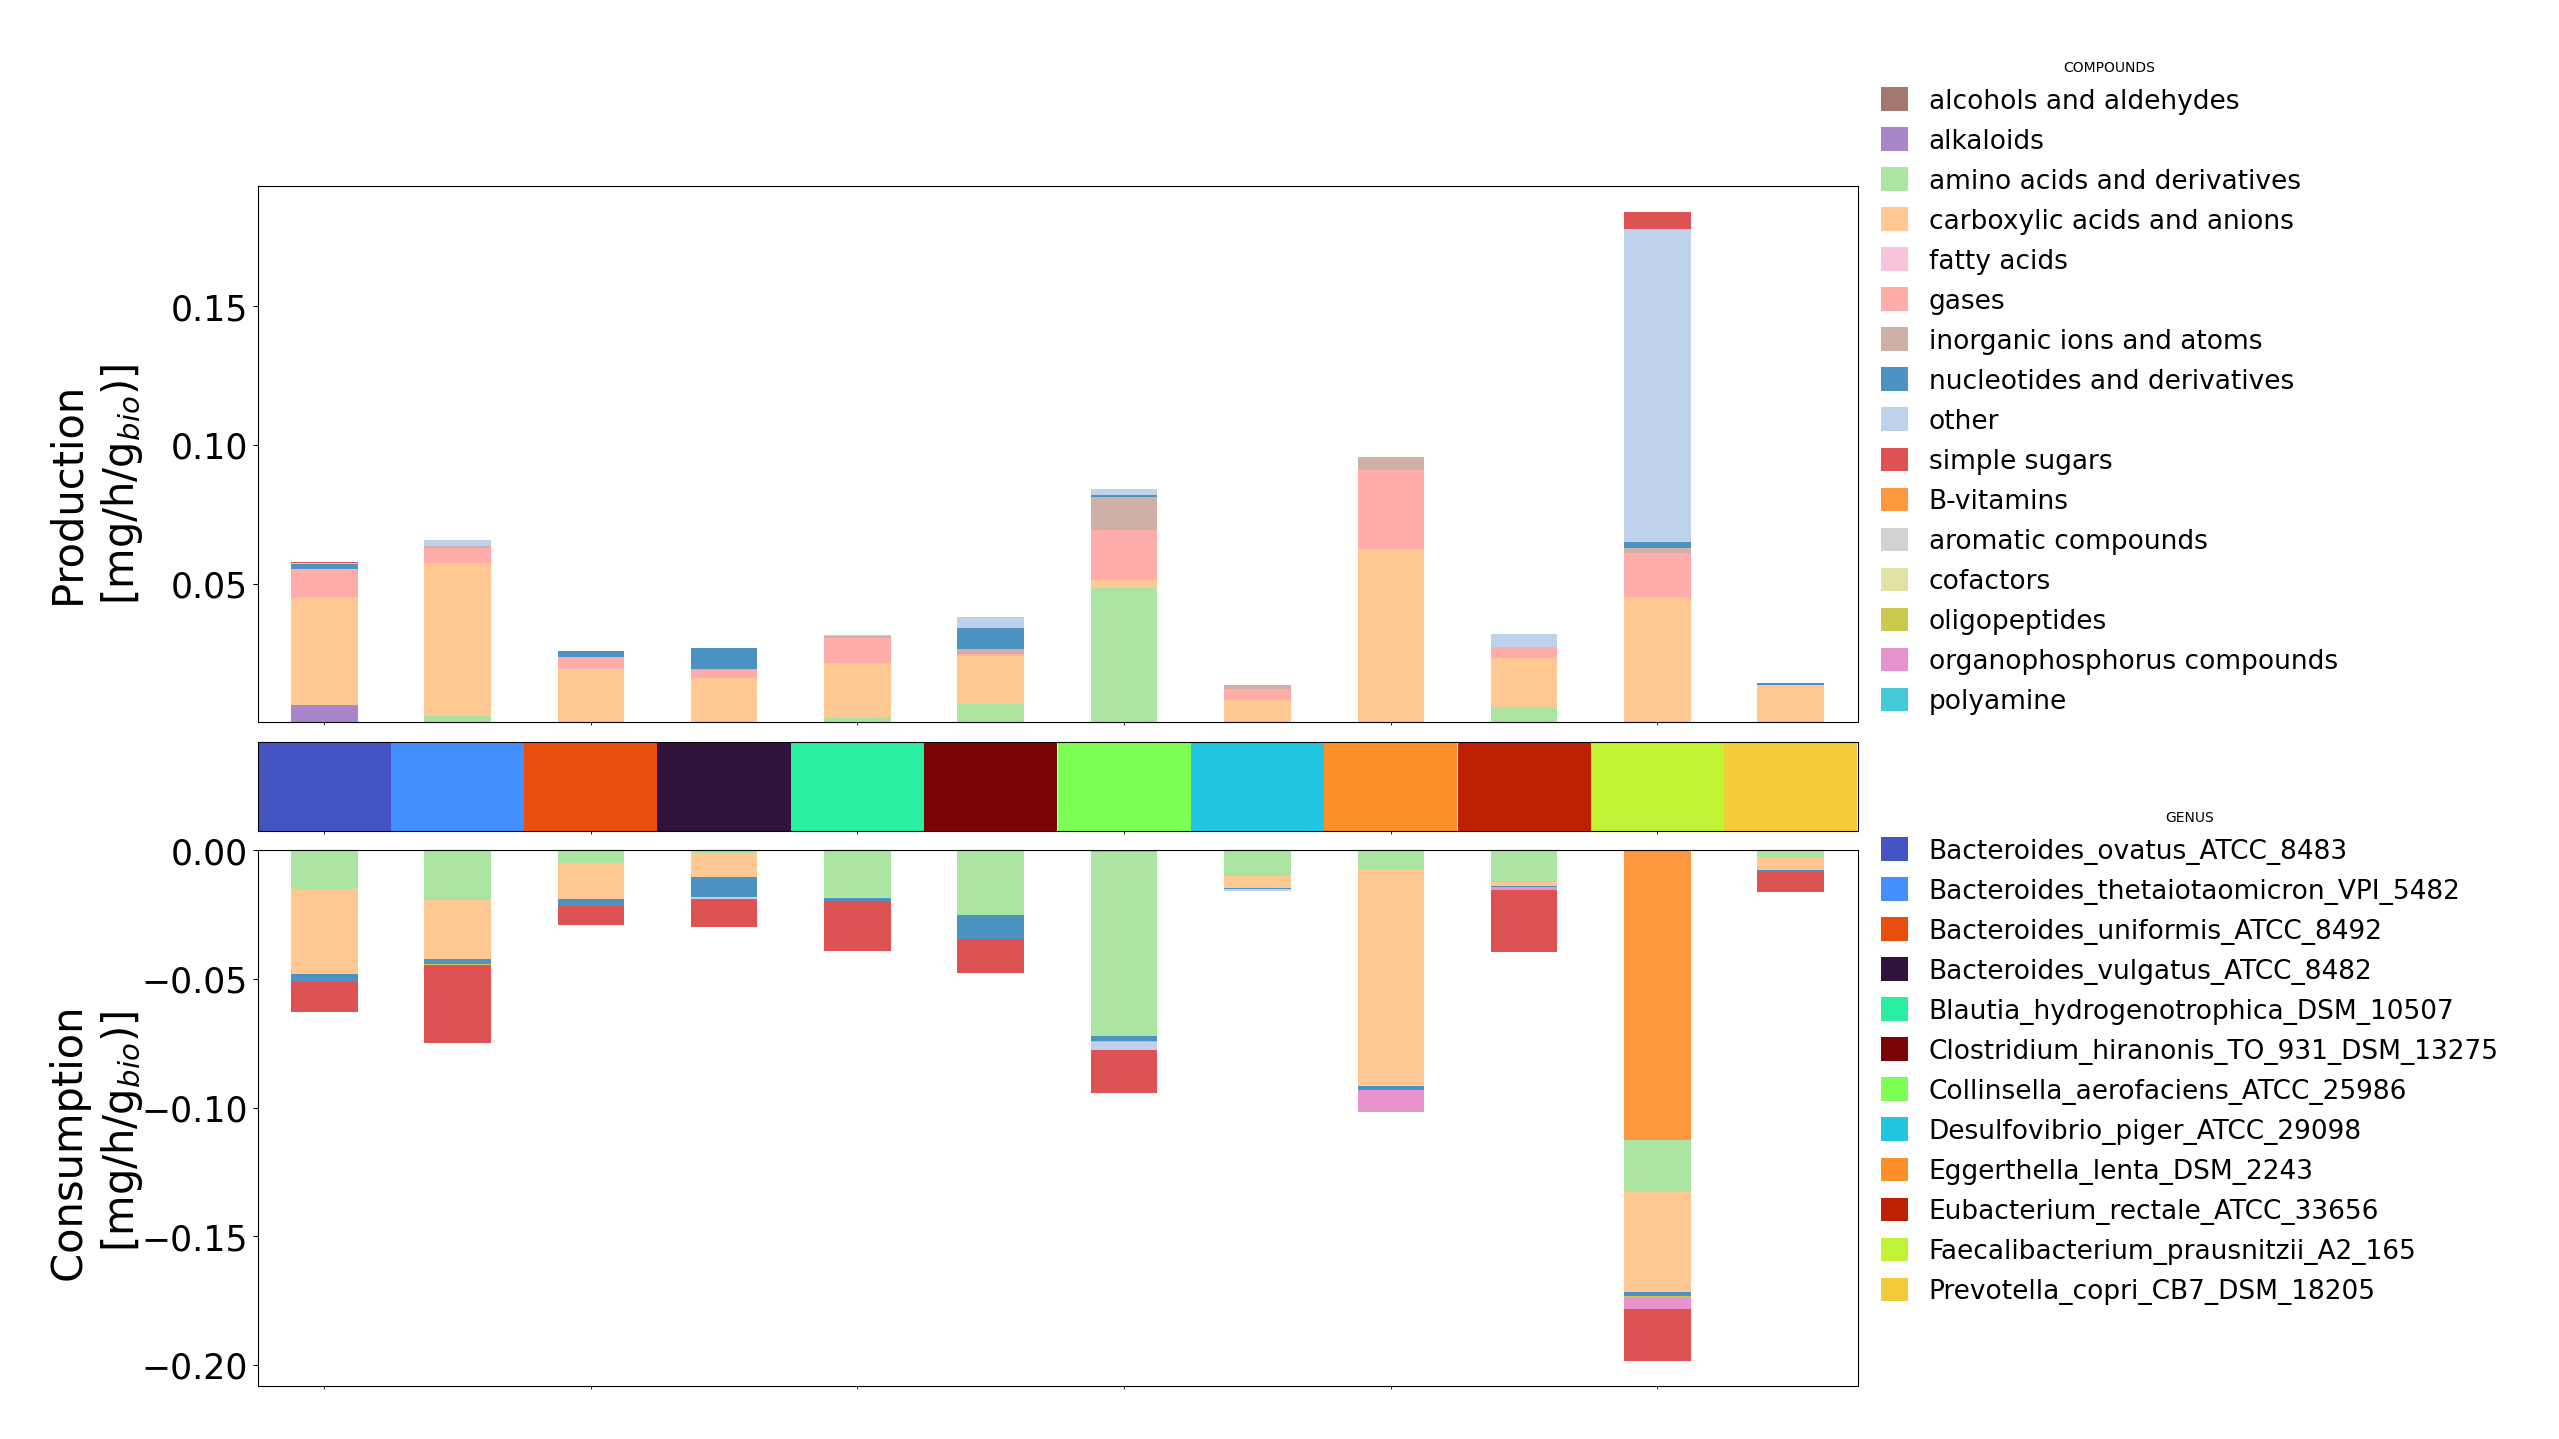

In [58]:
data_receiver_df,data_donor_df = data_uptake_prod(steadiercom_growth,community_id="NONE",compound_type=False,only_media=False,min_frequency=0.0)
plot_uptake_prod(data_receiver_df,data_donor_df,members_lut,super_classes_lut,title=None,legend=True)

(<Figure size 2000x1500 with 3 Axes>,
 {'Bacteroides_ovatus_ATCC_8483': np.float64(0.1),
  'Bacteroides_thetaiotaomicron_VPI_5482': np.float64(0.2),
  'Blautia_hydrogenotrophica_DSM_10507': np.float64(0.30000000000000004),
  'Clostridium_hiranonis_TO_931_DSM_13275': np.float64(0.4),
  'Collinsella_aerofaciens_ATCC_25986': np.float64(0.5),
  'Eggerthella_lenta_DSM_2243': np.float64(0.6),
  'Eubacterium_rectale_ATCC_33656': np.float64(0.7000000000000001),
  'Faecalibacterium_prausnitzii_A2_165': np.float64(0.8),
  'Desulfovibrio_piger_ATCC_29098': np.float64(0.9)})

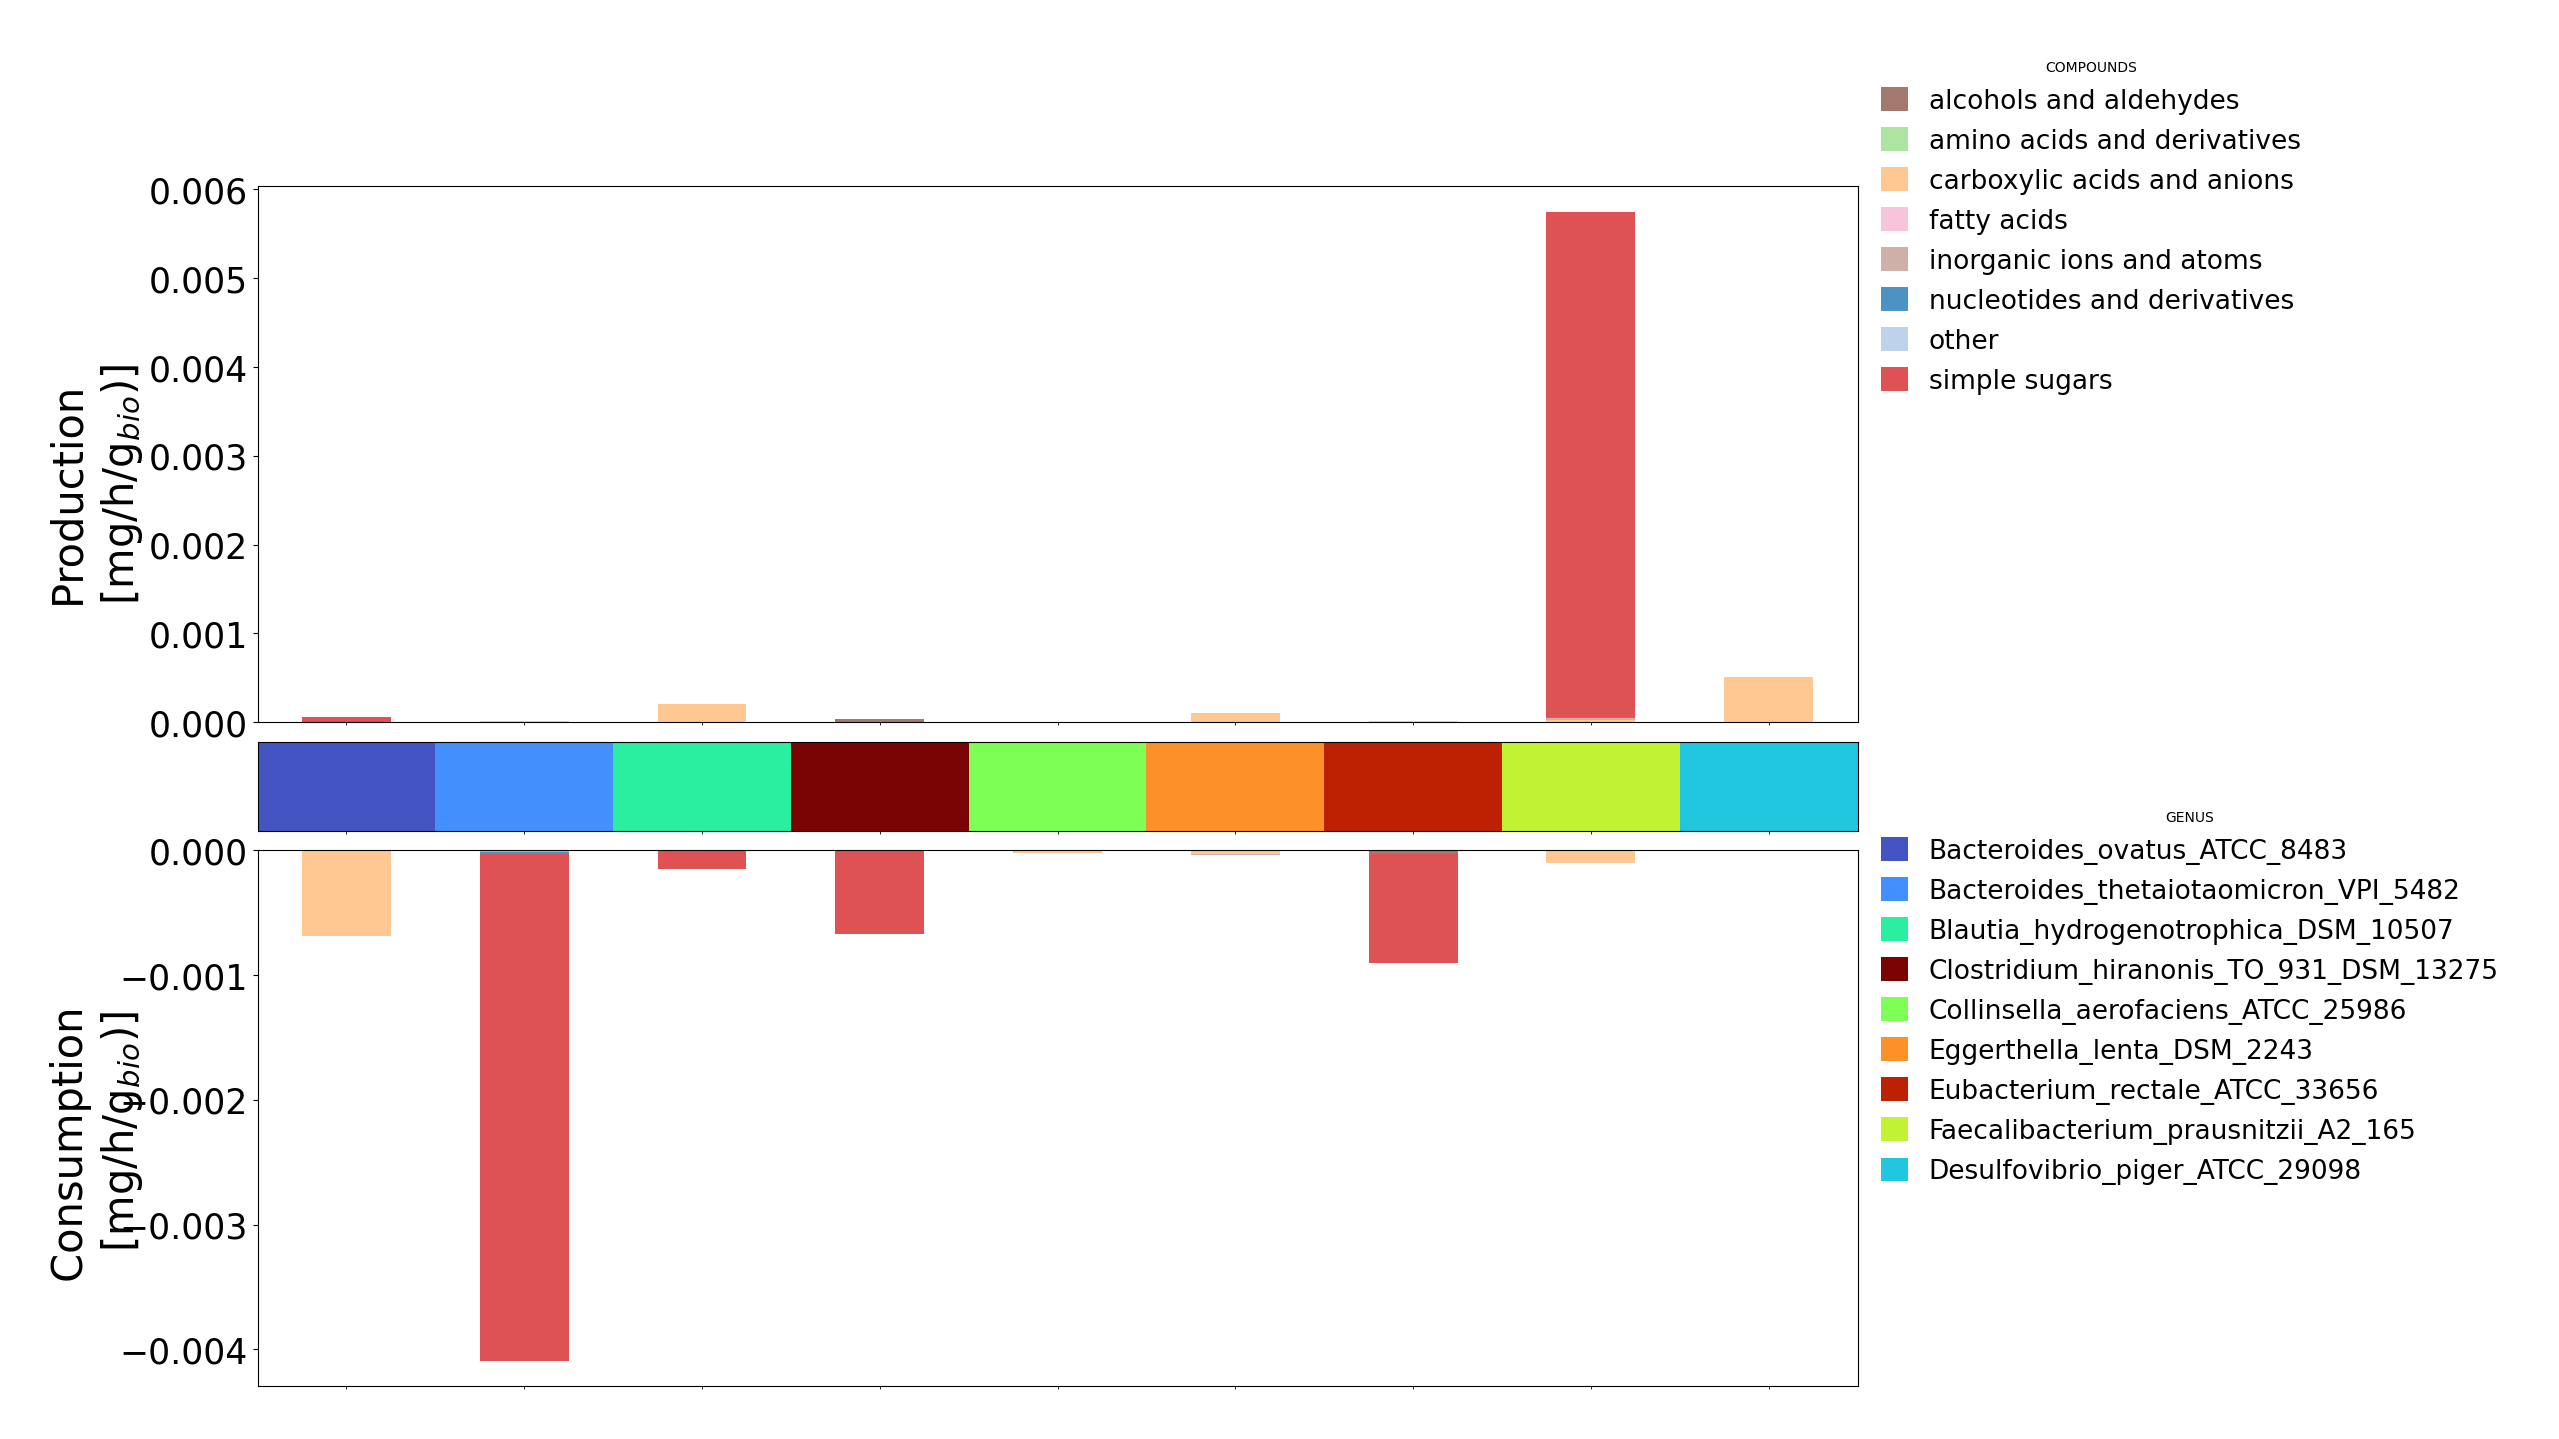

In [59]:
steadiercom_growth_inter = steadiercom_growth.query("receiver!='environment' & donor!='environment'")
data_receiver_df,data_donor_df = data_uptake_prod(steadiercom_growth_inter,community_id="NONE",compound_type=False,only_media=False,min_frequency=0.0)
plot_uptake_prod(data_receiver_df,data_donor_df,members_lut,super_classes_lut,title=None,legend=True)

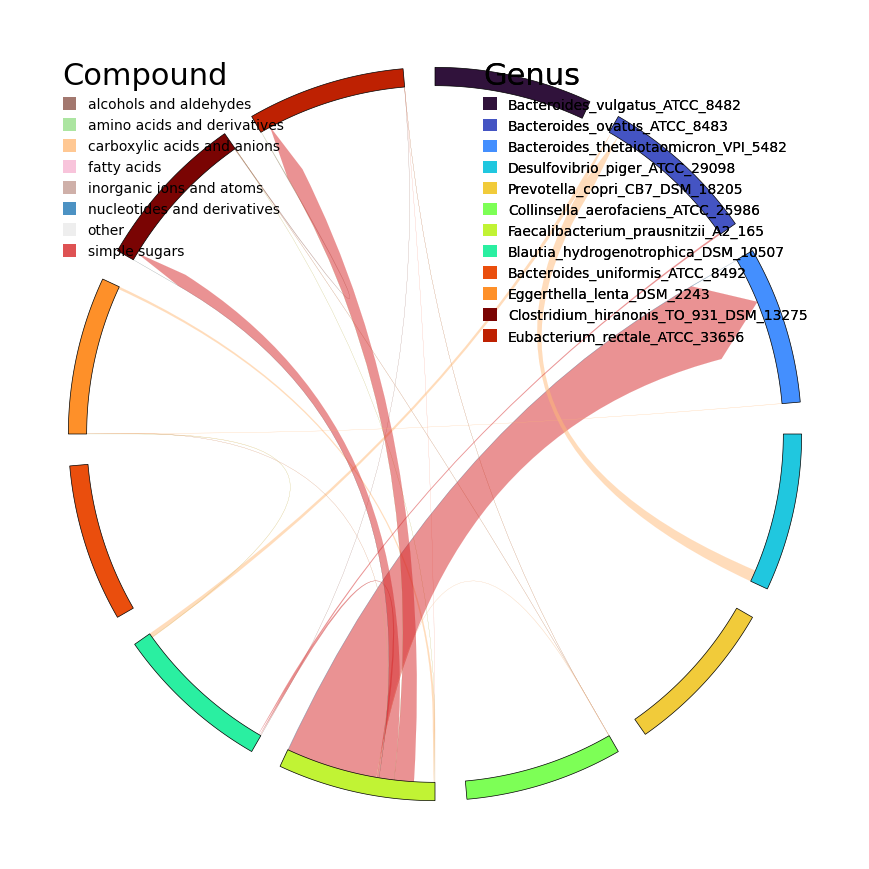

In [60]:
links,members,super_classes = circos_plot_process_data(steadiercom_growth,community_id="NONE",min_flux=0,compound_type=False,min_frequency=0.001) 

fig,mag2color,line_legend,genus_legend = plot_circos_plot(links,members,super_classes,members_lut,super_classes_lut,fontsize=22,title=None,extra_compounds=False,move_legend=0)
plt.subplots_adjust(right=0.8)


(<Figure size 2000x1500 with 3 Axes>,
 {'Bacteroides_ovatus_ATCC_8483': np.float64(0.1),
  'Bacteroides_thetaiotaomicron_VPI_5482': np.float64(0.19),
  'Bacteroides_uniformis_ATCC_8492': np.float64(0.28),
  'Bacteroides_vulgatus_ATCC_8482': np.float64(0.37),
  'Blautia_hydrogenotrophica_DSM_10507': np.float64(0.45999999999999996),
  'Clostridium_hiranonis_TO_931_DSM_13275': np.float64(0.5499999999999999),
  'Collinsella_aerofaciens_ATCC_25986': np.float64(0.64),
  'Desulfovibrio_piger_ATCC_29098': np.float64(0.73),
  'Eubacterium_rectale_ATCC_33656': np.float64(0.82),
  'Faecalibacterium_prausnitzii_A2_165': np.float64(0.9099999999999999)})

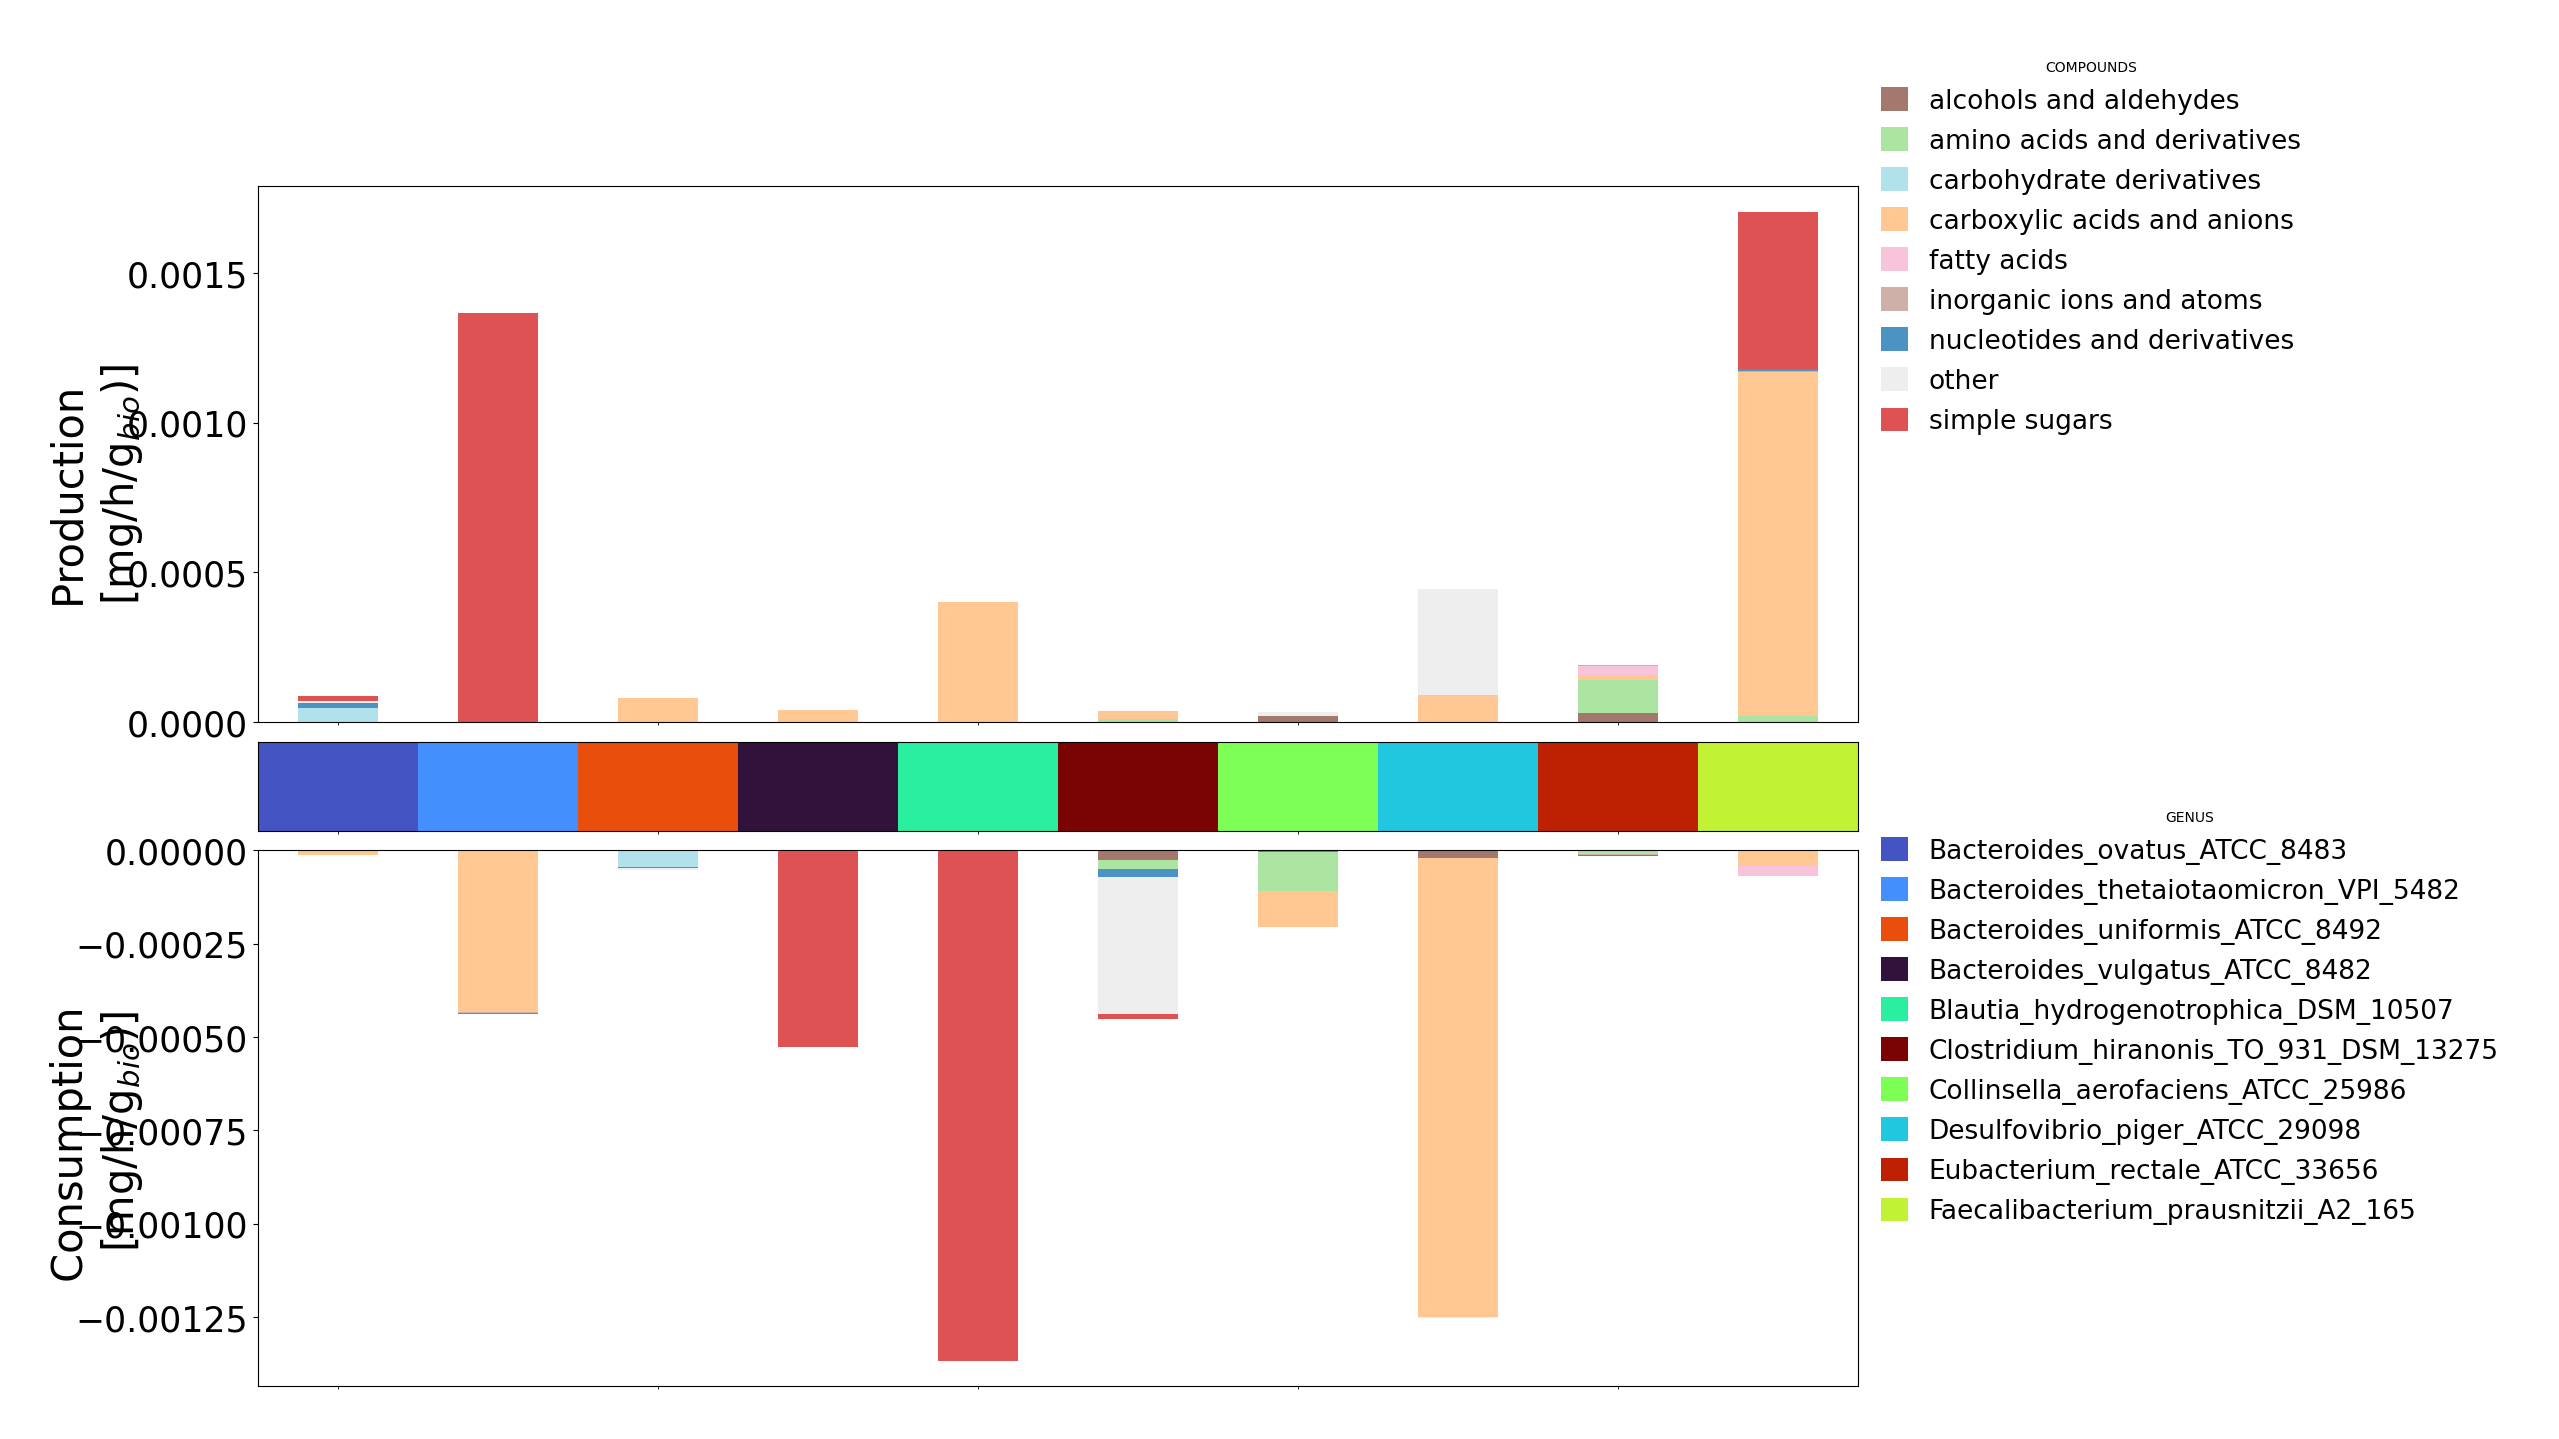

In [61]:
steadiercom_growth_inter = steadiercom_growth.query("receiver!='environment' & donor!='environment'")
data_receiver_df,data_donor_df = data_uptake_prod(steadiercom_growth_inter,community_id="EL-",compound_type=False,only_media=False,min_frequency=0.0)
plot_uptake_prod(data_receiver_df,data_donor_df,members_lut,super_classes_lut,title=None,legend=True)

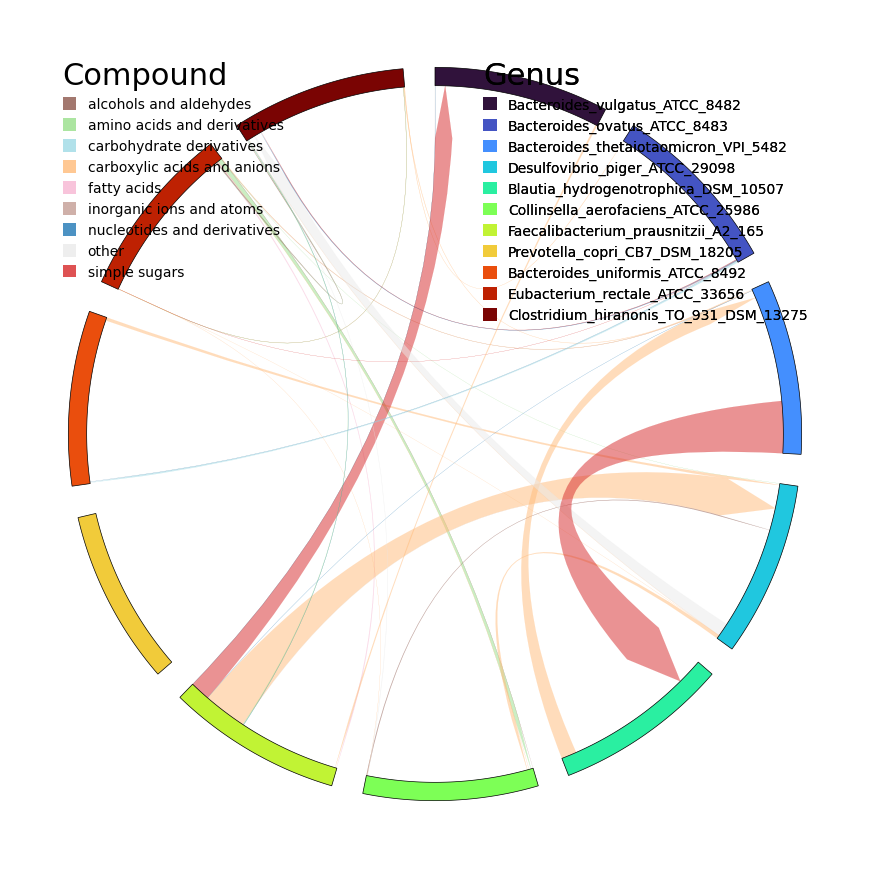

In [62]:

links,members,super_classes = circos_plot_process_data(steadiercom_growth,community_id="EL-",min_flux=0,compound_type=False,min_frequency=0.001) 
fig,mag2color,line_legend,genus_legend = plot_circos_plot(links,members,super_classes,members_lut,super_classes_lut,fontsize=22,title=None,extra_compounds=False,move_legend=0)
plt.subplots_adjust(right=0.8)


(<Figure size 2000x1500 with 3 Axes>,
 {'Bacteroides_thetaiotaomicron_VPI_5482': np.float64(0.1),
  'Bacteroides_uniformis_ATCC_8492': np.float64(0.18181818181818182),
  'Bacteroides_vulgatus_ATCC_8482': np.float64(0.26363636363636367),
  'Blautia_hydrogenotrophica_DSM_10507': np.float64(0.34545454545454546),
  'Clostridium_hiranonis_TO_931_DSM_13275': np.float64(0.42727272727272725),
  'Collinsella_aerofaciens_ATCC_25986': np.float64(0.509090909090909),
  'Desulfovibrio_piger_ATCC_29098': np.float64(0.5909090909090909),
  'Eggerthella_lenta_DSM_2243': np.float64(0.6727272727272727),
  'Eubacterium_rectale_ATCC_33656': np.float64(0.7545454545454545),
  'Faecalibacterium_prausnitzii_A2_165': np.float64(0.8363636363636363),
  'Prevotella_copri_CB7_DSM_18205': np.float64(0.9181818181818181)})

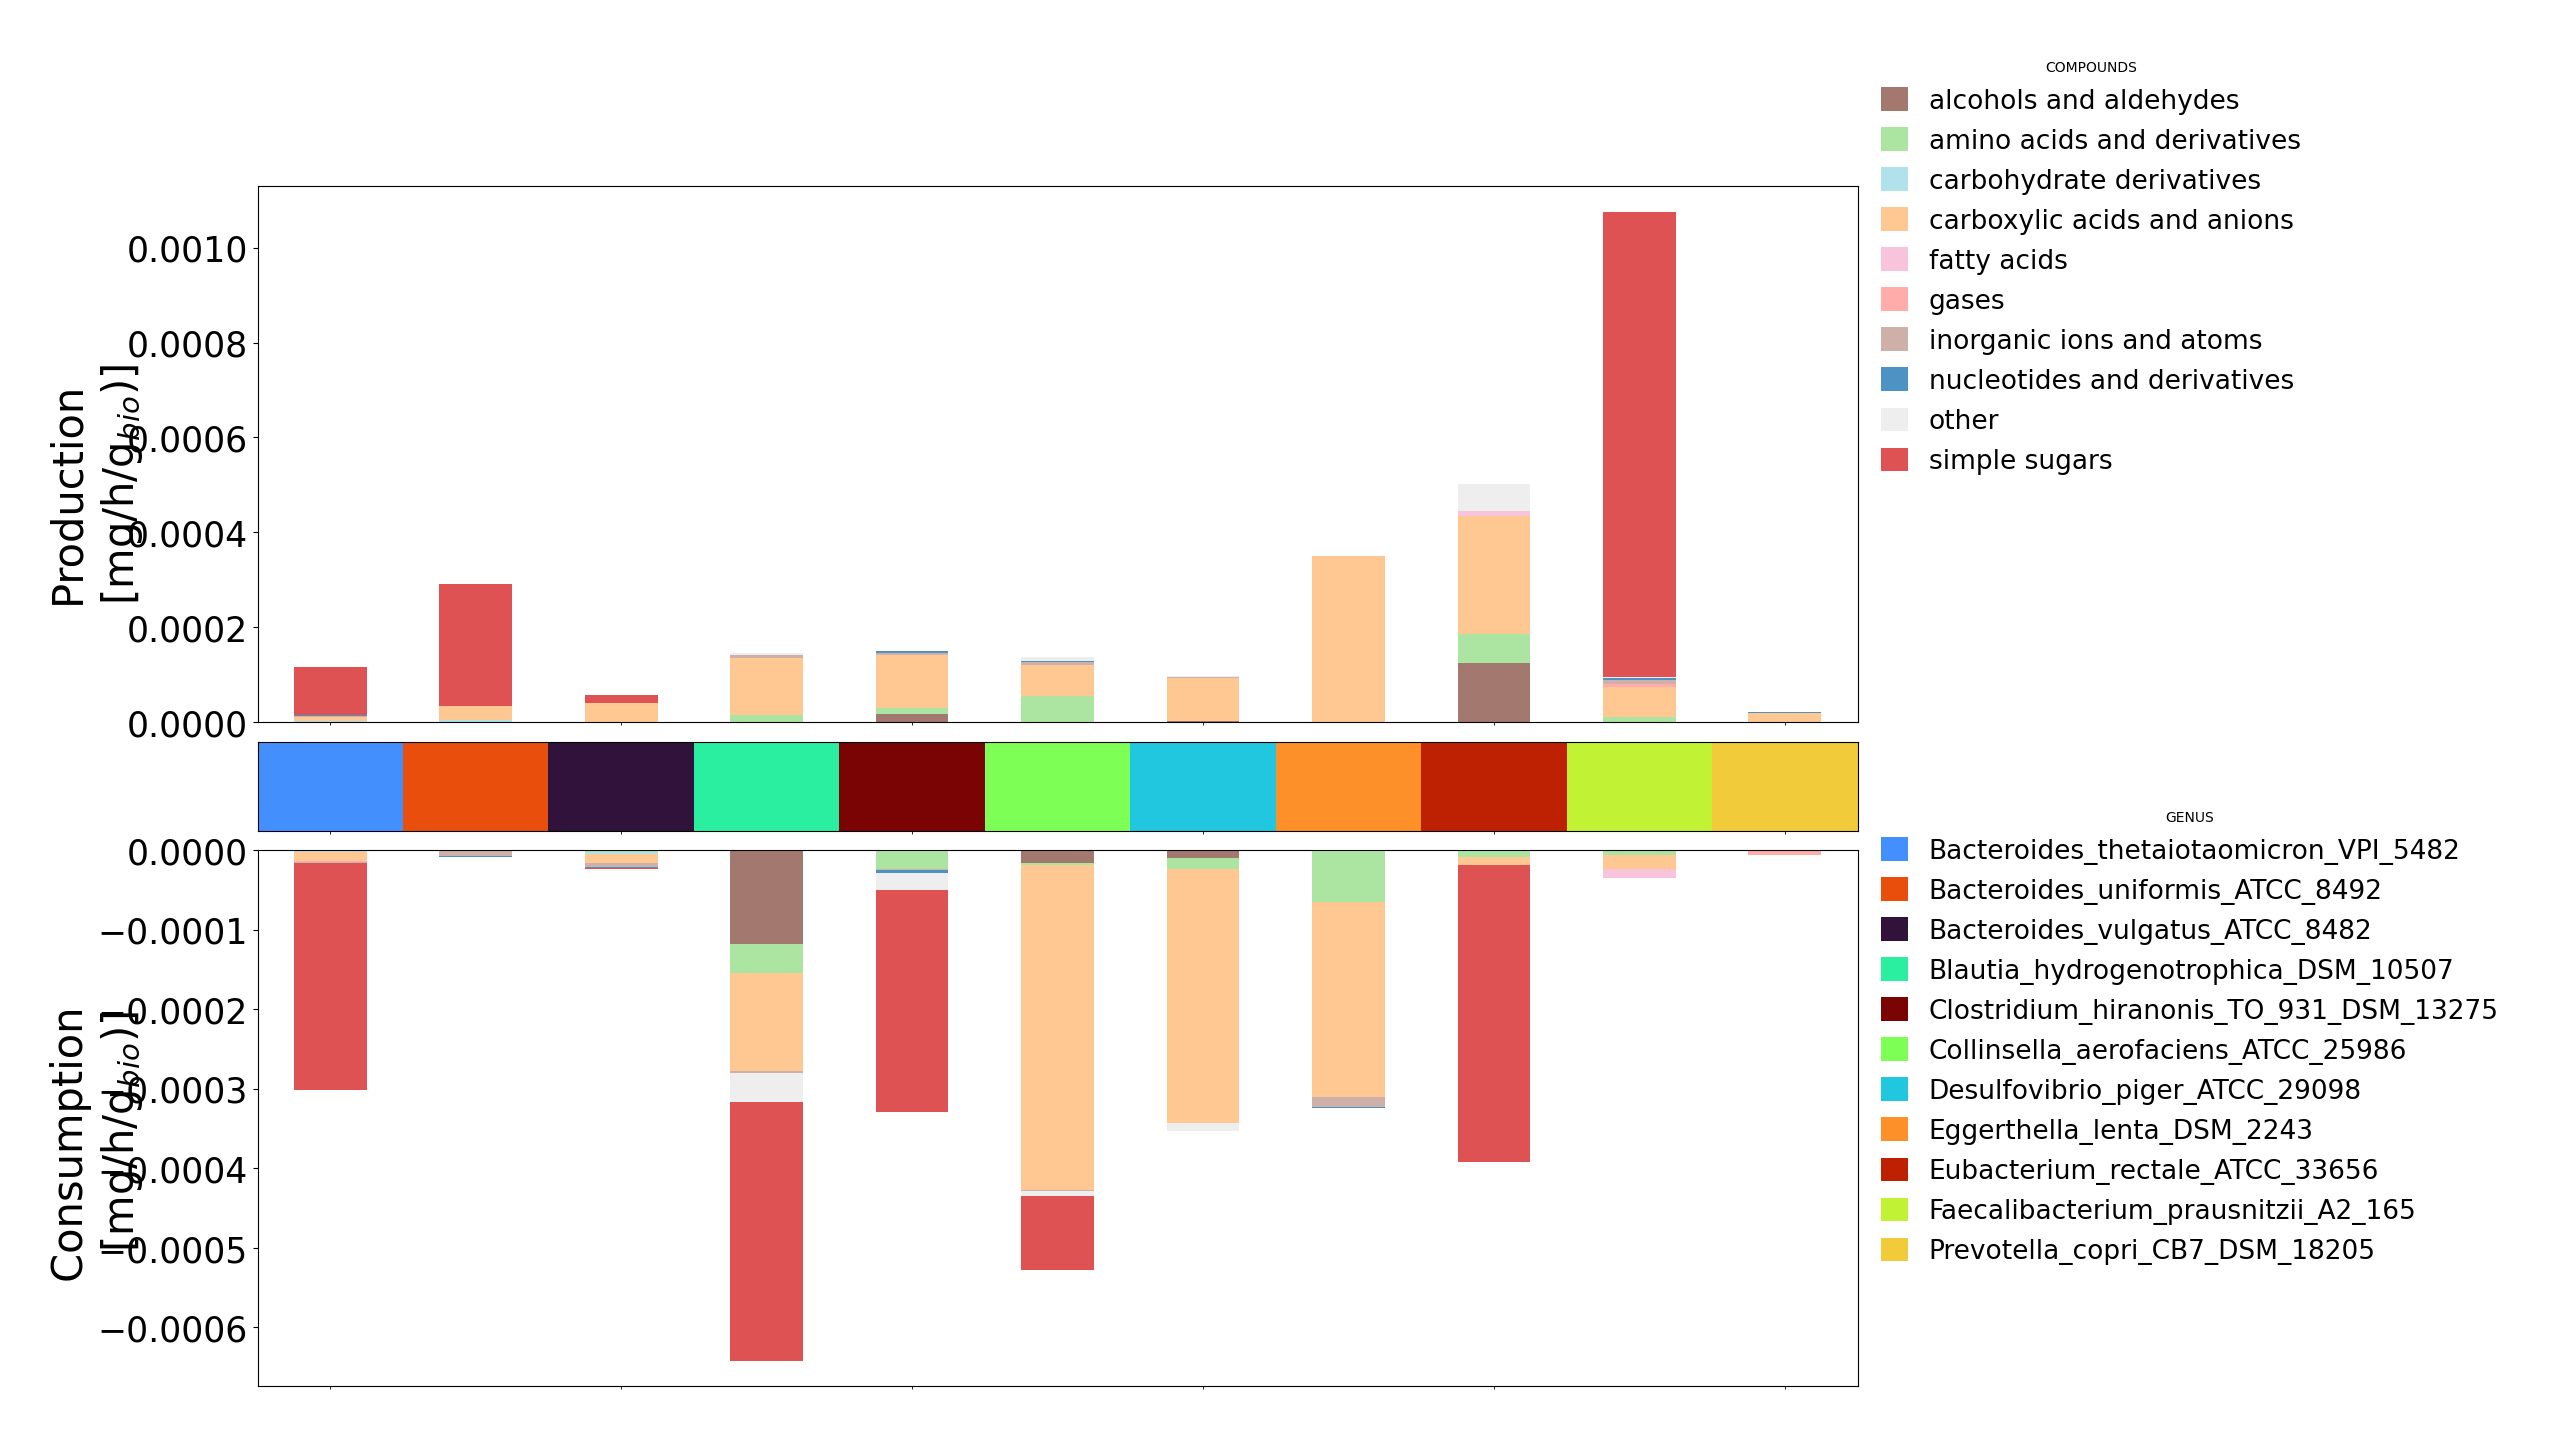

In [63]:
steadiercom_growth_inter = steadiercom_growth.query("receiver!='environment' & donor!='environment'")
data_receiver_df,data_donor_df = data_uptake_prod(steadiercom_growth_inter,community_id="BO-",compound_type=False,only_media=False,min_frequency=0.0)
plot_uptake_prod(data_receiver_df,data_donor_df,members_lut,super_classes_lut,title=None,legend=True)

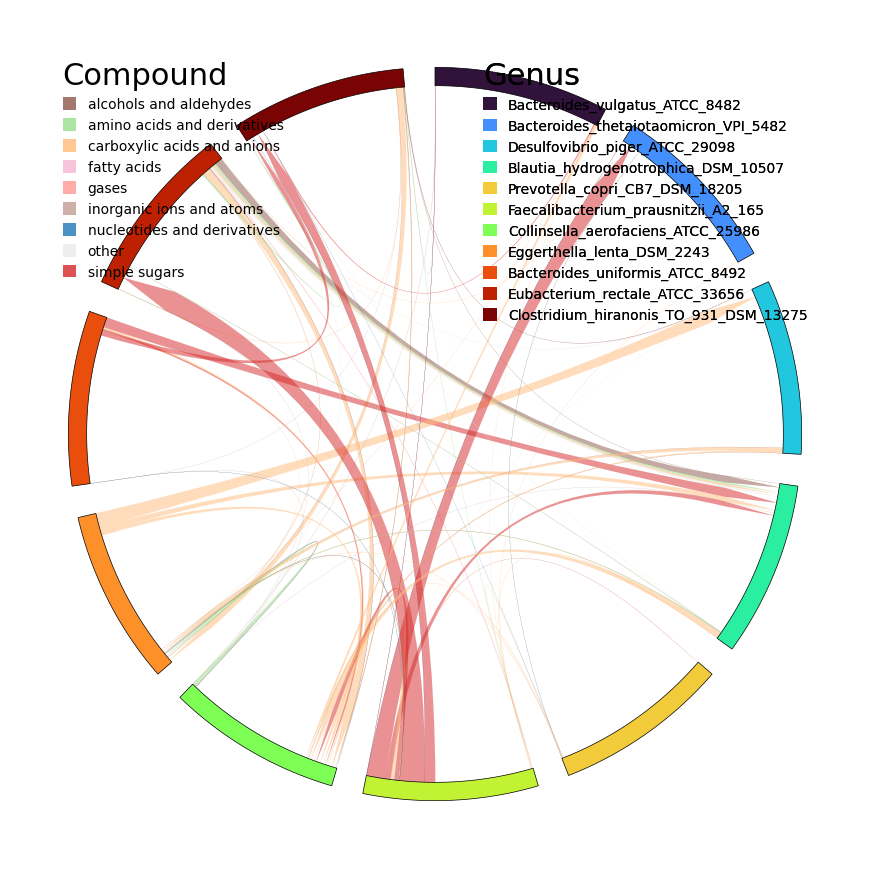

In [64]:

links,members,super_classes = circos_plot_process_data(steadiercom_growth,community_id="BO-",min_flux=0,compound_type=False,min_frequency=0.001) 
fig,mag2color,line_legend,genus_legend = plot_circos_plot(links,members,super_classes,members_lut,super_classes_lut,fontsize=22,title=None,extra_compounds=False,move_legend=0)
plt.subplots_adjust(right=0.8)


(<Figure size 2000x1500 with 3 Axes>,
 {'Bacteroides_ovatus_ATCC_8483': np.float64(0.1),
  'Bacteroides_thetaiotaomicron_VPI_5482': np.float64(0.18181818181818182),
  'Bacteroides_uniformis_ATCC_8492': np.float64(0.26363636363636367),
  'Bacteroides_vulgatus_ATCC_8482': np.float64(0.34545454545454546),
  'Clostridium_hiranonis_TO_931_DSM_13275': np.float64(0.42727272727272725),
  'Collinsella_aerofaciens_ATCC_25986': np.float64(0.509090909090909),
  'Desulfovibrio_piger_ATCC_29098': np.float64(0.5909090909090909),
  'Eggerthella_lenta_DSM_2243': np.float64(0.6727272727272727),
  'Eubacterium_rectale_ATCC_33656': np.float64(0.7545454545454545),
  'Faecalibacterium_prausnitzii_A2_165': np.float64(0.8363636363636363),
  'Prevotella_copri_CB7_DSM_18205': np.float64(0.9181818181818181)})

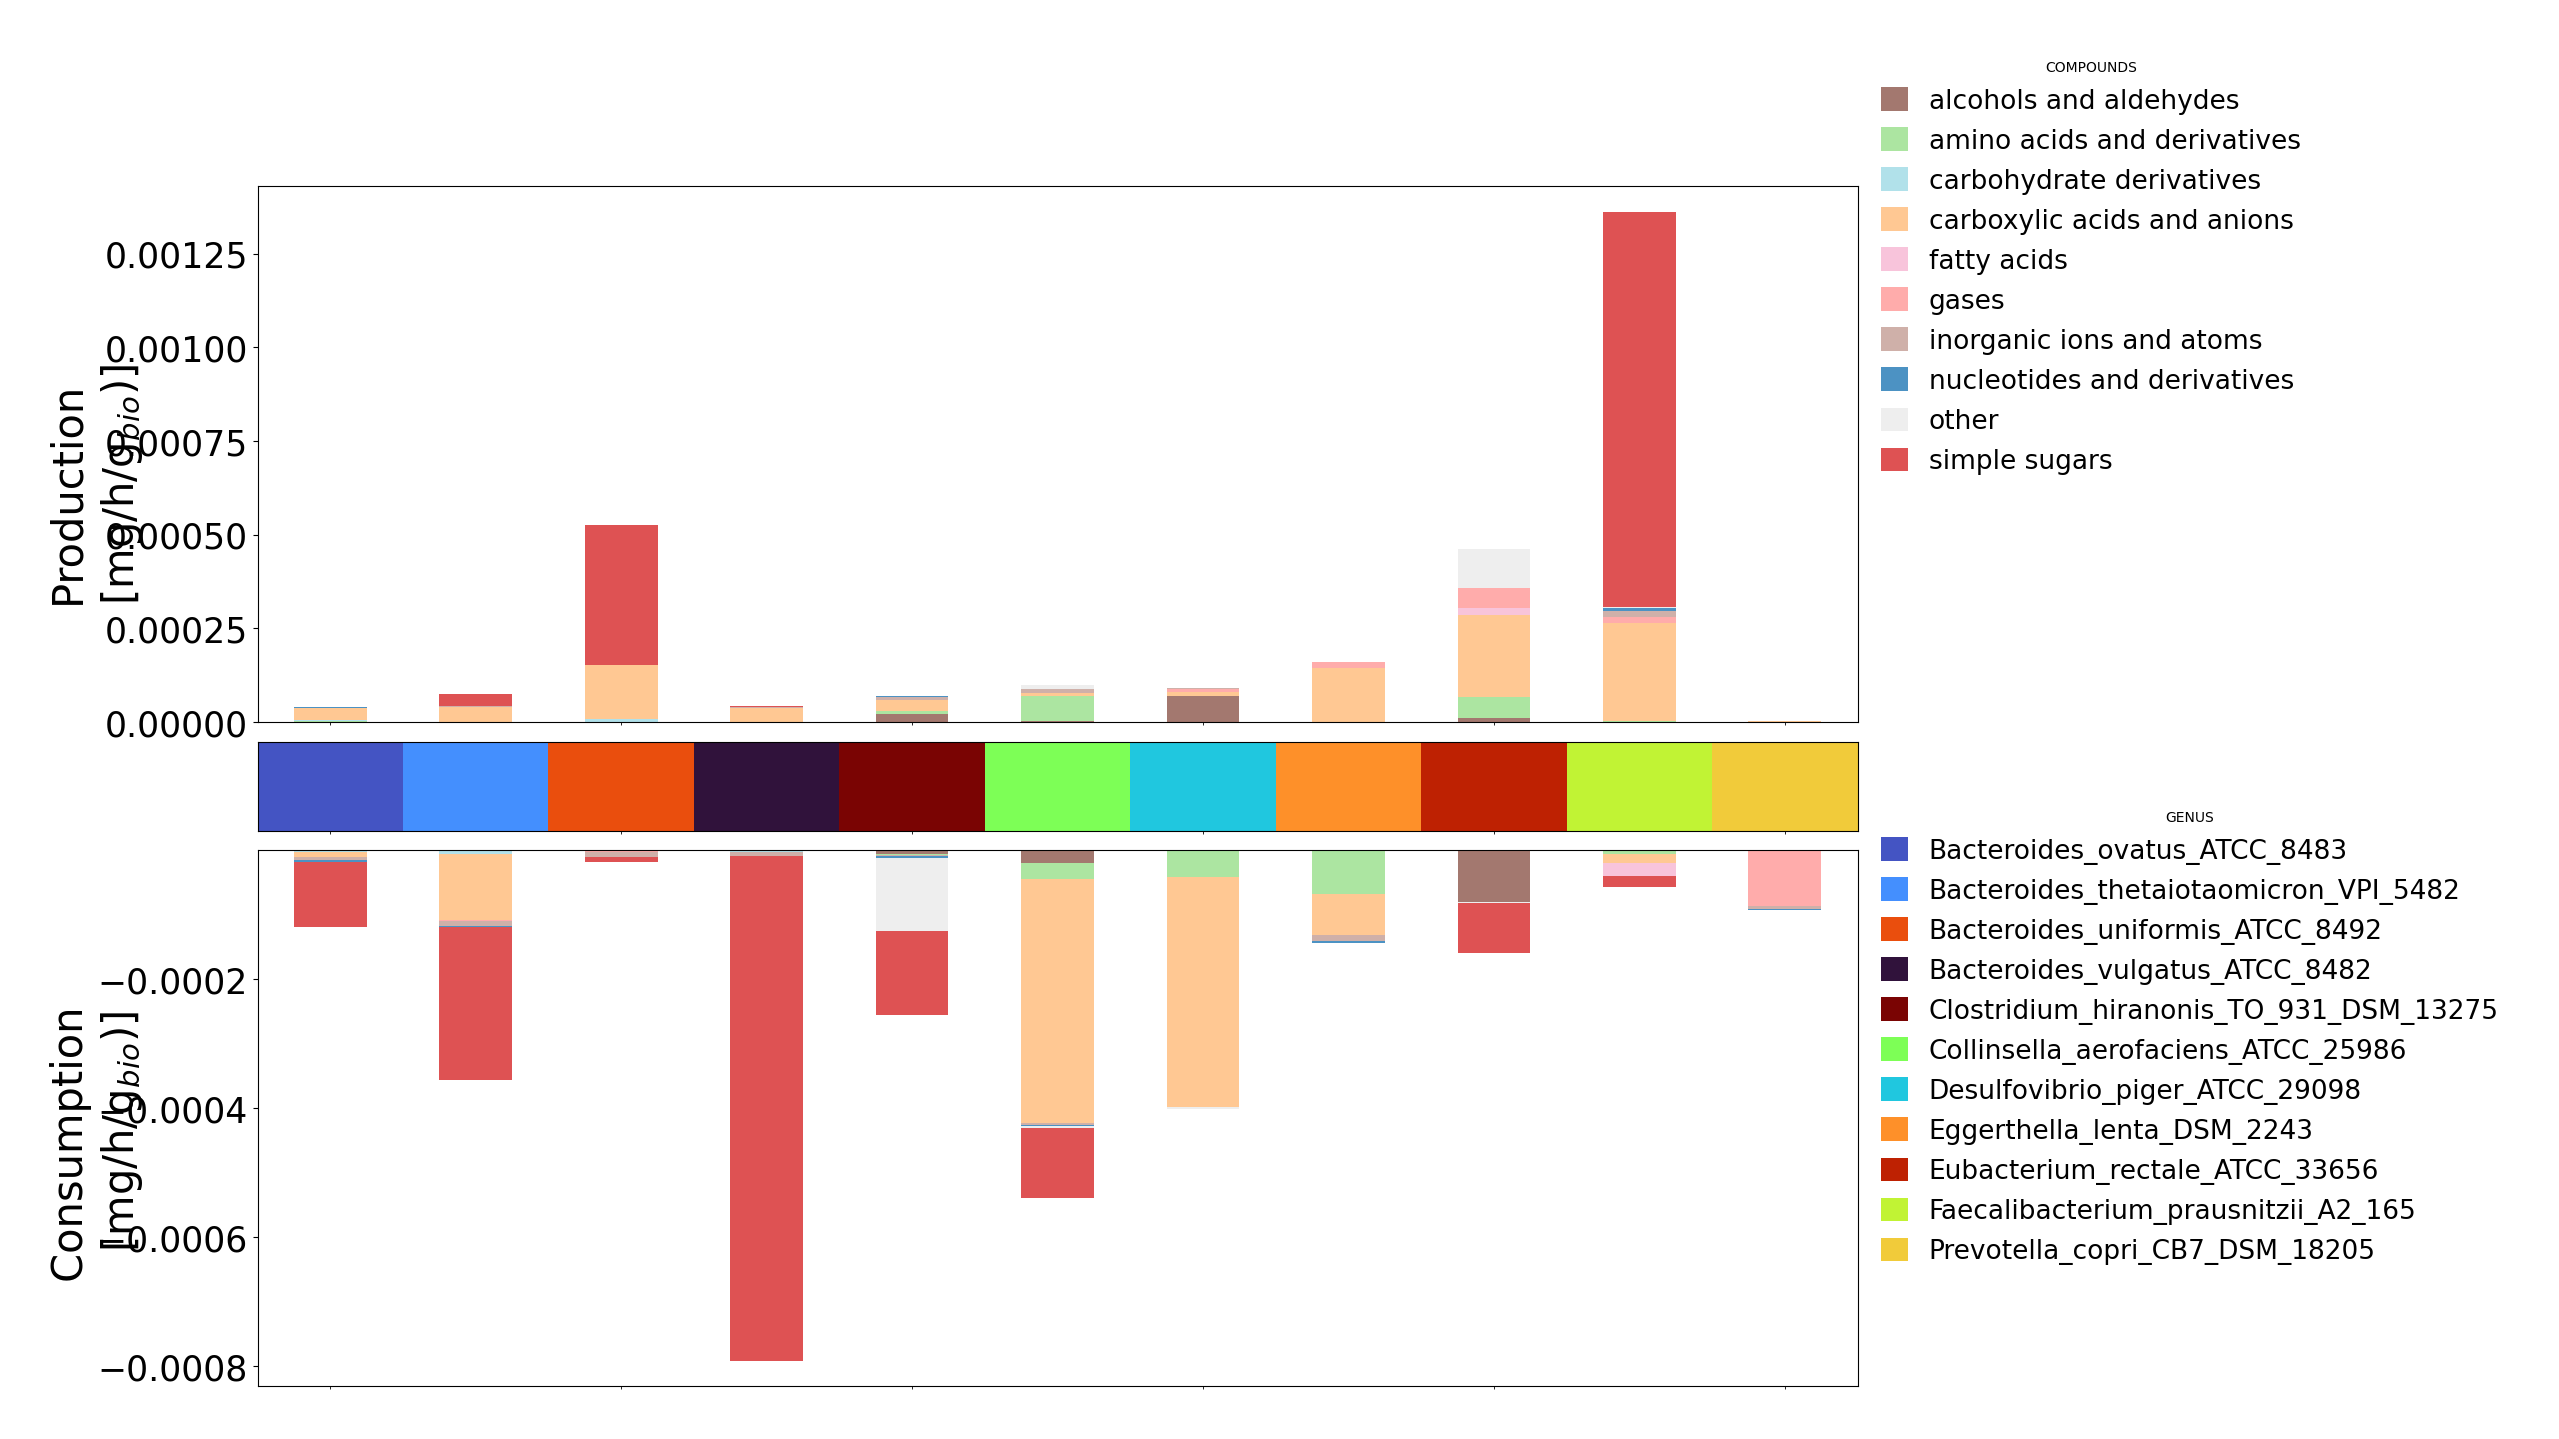

In [65]:
steadiercom_growth_inter = steadiercom_growth.query("receiver!='environment' & donor!='environment'")
data_receiver_df,data_donor_df = data_uptake_prod(steadiercom_growth_inter,community_id="BH-",compound_type=False,only_media=False,min_frequency=0.0)
plot_uptake_prod(data_receiver_df,data_donor_df,members_lut,super_classes_lut,title=None,legend=True)

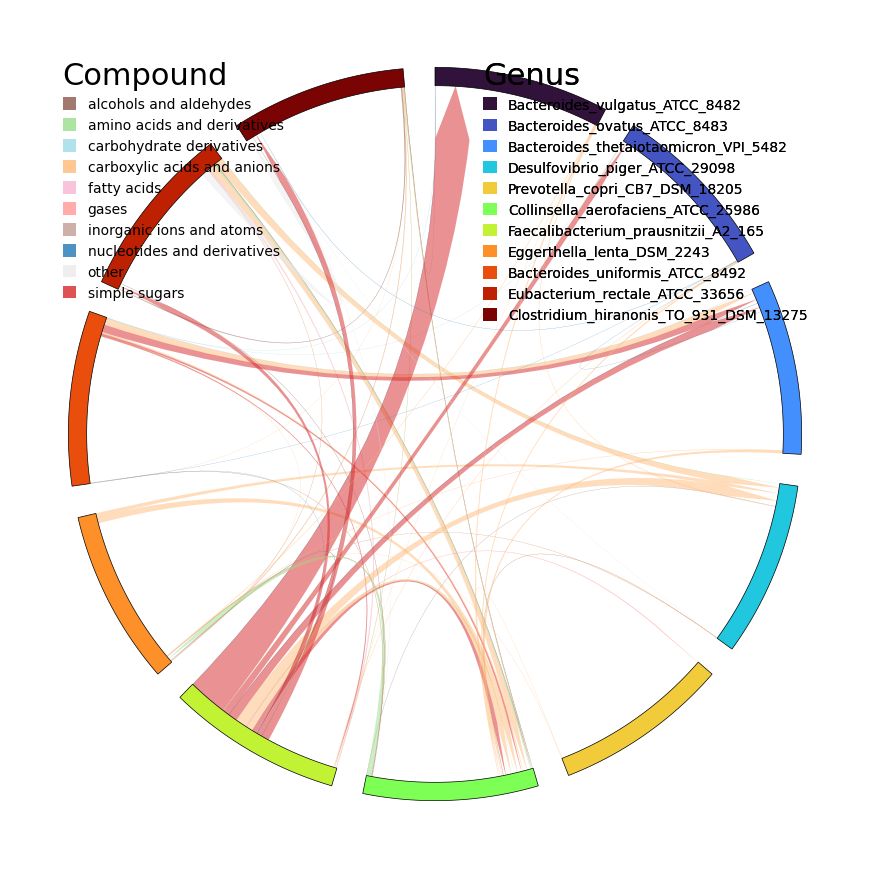

In [66]:

links,members,super_classes = circos_plot_process_data(steadiercom_growth,community_id="BH-",min_flux=0,compound_type=False,min_frequency=0.001) 
fig,mag2color,line_legend,genus_legend = plot_circos_plot(links,members,super_classes,members_lut,super_classes_lut,fontsize=22,title=None,extra_compounds=False,move_legend=0)
plt.subplots_adjust(right=0.8)


In [81]:
steadiercom_growth_inter = steadiercom_growth.query("donor!='environment' & receiver!='environment'")
steadiercom_growth_inter

,donor,receiver,compound,mass_rate,rate,frequency,community,medium
63,Desulfovibrio_piger_ATCC_29098,Clostridium_hiranonis_TO_931_DSM_13275,M_etoh__91__e__93__,1.101552e-01,2.391132e+00,0.010000,PC-,LB_extend
66,Clostridium_hiranonis_TO_931_DSM_13275,Desulfovibrio_piger_ATCC_29098,M_acald__91__e__93__,1.053351e-01,2.391132e+00,0.010000,PC-,LB_extend
124,Faecalibacterium_prausnitzii_A2_165,Clostridium_hiranonis_TO_931_DSM_13275,M_fru__91__e__93__,1.737158e-02,9.642552e-02,0.010000,PC-,LB_extend
139,Collinsella_aerofaciens_ATCC_25986,Eggerthella_lenta_DSM_2243,M_orn__91__e__93__,1.031937e-02,7.749113e-02,0.030000,PC-,LB_extend
141,Eubacterium_rectale_ATCC_33656,Collinsella_aerofaciens_ATCC_25986,M_gln_L__91__e__93__,1.020746e-02,6.984515e-02,0.010000,PC-,LB_extend
...,...,...,...,...,...,...,...,...
661,Bacteroides_uniformis_ATCC_8492,Faecalibacterium_prausnitzii_A2_165,M_succ__91__e__93__,6.481769e-07,5.584265e-06,0.000667,BO-,LB_extend
662,Eubacterium_rectale_ATCC_33656,Prevotella_copri_CB7_DSM_18205,M_nh4__91__e__93__,5.678949e-07,3.148273e-05,0.000667,BO-,LB_extend
663,Clostridium_hiranonis_TO_931_DSM_13275,Bacteroides_vulgatus_ATCC_8482,M_dad_2__91__e__93__,5.211512e-07,2.074305e-06,0.000667,BO-,LB_extend
664,Bacteroides_uniformis_ATCC_8492,Blautia_hydrogenotrophica_DSM_10507,M_nh4__91__e__93__,1.819662e-09,1.008777e-07,0.000667,BO-,LB_extend


In [97]:
cogrowers = ['Prevotella_copri_CB7_DSM_18205','Eubacterium_rectale_ATCC_33656','Clostridium_hiranonis_TO_931_DSM_13275','Faecalibacterium_prausnitzii_A2_165','Eggerthella_lenta_DSM_2243','Collinsella_aerofaciens_ATCC_25986','Blautia_hydrogenotrophica_DSM_10507']
SC_co_growers = steadiercom_growth_inter[(steadiercom_growth_inter.donor.isin(cogrowers)) & (steadiercom_growth_inter.receiver.isin(cogrowers)) ]
SC_co_growers.groupby(['donor']).apply(lambda x: x.nlargest(8, 'frequency'))


/var/folders/mc/1rm74nkd4s78l46281nyt5wm0000gn/T/ipykernel_93845/2739966231.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  SC_co_growers.groupby(['donor']).apply(lambda x: x.nlargest(8, 'frequency'))


donor  \
donor                                                                                
Blautia_hydrogenotrophica_DSM_10507    154     Blautia_hydrogenotrophica_DSM_10507   
                                       351     Blautia_hydrogenotrophica_DSM_10507   
                                       152     Blautia_hydrogenotrophica_DSM_10507   
                                       322     Blautia_hydrogenotrophica_DSM_10507   
                                       433     Blautia_hydrogenotrophica_DSM_10507   
                                       250     Blautia_hydrogenotrophica_DSM_10507   
                                       322     Blautia_hydrogenotrophica_DSM_10507   
                                       335     Blautia_hydrogenotrophica_DSM_10507   
Clostridium_hiranonis_TO_931_DSM_13275 304  Clostridium_hiranonis_TO_931_DSM_13275   
                                       274  Clostridium_hiranonis_TO_931_DSM_13275   
                                       277  Clostridium_hiranonis_TO_931_DSM_13275   
                                       279  Clostridium_hiranonis_TO_931_DSM_13275   
                                       326  Clostridium_hiranonis_TO_931_DSM_13275   
                                       356  Clostridium_hiranonis_TO_931_DSM_13275   
                                       407  Clostridium_hiranonis_TO_931_DSM_13275   
                                       326  Clostridium_hiranonis_TO_931_DSM_13275   
Collinsella_aerofaciens_ATCC_25986     139      Collinsella_aerofaciens_ATCC_25986   
                                       332      Collinsella_aerofaciens_ATCC_25986   
                                       135      Collinsella_aerofaciens_ATCC_25986   
                                       154      Collinsella_aerofaciens_ATCC_25986   
                                       311      Collinsella_aerofaciens_ATCC_25986   
                                       152      Collinsella_aerofaciens_ATCC_25986   
                                       328      Collinsella_aerofaciens_ATCC_25986   
                                       118      Collinsella_aerofaciens_ATCC_25986   
Eggerthella_lenta_DSM_2243             321              Eggerthella_lenta_DSM_2243   
                                       357              Eggerthella_lenta_DSM_2243   
                                       117              Eggerthella_lenta_DSM_2243   
                                       322              Eggerthella_lenta_DSM_2243   
                                       234              Eggerthella_lenta_DSM_2243   
                                       317              Eggerthella_lenta_DSM_2243   
                                       141              Eggerthella_lenta_DSM_2243   
                                       402              Eggerthella_lenta_DSM_2243   
Eubacterium_rectale_ATCC_33656         317          Eubacterium_rectale_ATCC_33656   
                                       176          Eubacterium_rectale_ATCC_33656   
                                       310          Eubacterium_rectale_ATCC_33656   
                                       309          Eubacterium_rectale_ATCC_33656   
                                       185          Eubacterium_rectale_ATCC_33656   
                                       163          Eubacterium_rectale_ATCC_33656   
                                       236          Eubacterium_rectale_ATCC_33656   
                                       242          Eubacterium_rectale_ATCC_33656   
Faecalibacterium_prausnitzii_A2_165    388     Faecalibacterium_prausnitzii_A2_165   
                                       423     Faecalibacterium_prausnitzii_A2_165   
                                       378     Faecalibacterium_prausnitzii_A2_165   
                                       366     Faecalibacterium_prausnitzii_A2_165   
                                       369     Faecalibacterium_prausnitzii_A2_165   
                                   

### Comparison between SteadierCom and experimental results

In [11]:
import pandas as pd
import numpy as np
import json
import csv
import warnings
from os import listdir
from collections import defaultdict

import matplotlib.pyplot as plt
import seaborn as sns

import scipy as sp
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,recall_score,precision_score,classification_report

import sys

sys.path.append("../functions/")

import compare_exp_sim

In [12]:
%load_ext autoreload
%autoreload 2

#### Mapping names to seed ids (seem to have a good overlap)

In [13]:
with open("../data/Venturelli2018/generated/metid2metname.json") as file:
    metid2metname = json.load(file)
    
with open("../data/Venturelli2018/generated/metname2metanetx.json") as file:
    metname2metanetx = json.load(file)
    
with open("../data/Venturelli2018/generated/metname_groups.json") as file:
    metname_groups = json.load(file)

with open("../data/Venturelli2018/generated/metname2group.json") as file:
    metname2group = json.load(file)

with open("../data/Venturelli2018/generated/metid2group.json") as file:
    metid2group = json.load(file)

In [14]:
len(set(metname2metanetx.keys())-set(metid2metname.values()))

33

**Metabolomics**

In [15]:
dataset4 = pd.read_excel("../data/Venturelli2018/msb178157-sup-0005-datasetev4.xlsx",sheet_name="Dataset EV4",index_col=0)
signal_exp = compare_exp_sim.prepare_exp_met_venturelli(dataset4,metname_groups,metname2group)

**Load steadiercom results**

In [16]:
dfs = []
for file in listdir("../output/Venturelli2018/results_steadiercom/results_growth_abundance_test/"):
    if file.endswith(".tsv"):
        df = pd.read_csv("../output/Venturelli2018/results_steadiercom/results_growth_abundance_test/"+file,sep="\t")
        dfs.append(df)
steadiercom_growth_abundance = pd.concat(dfs)
steadiercom_growth_abundance = steadiercom_growth_abundance[steadiercom_growth_abundance.community=="NONE"]


dfs = []
for file in listdir("../output/Venturelli2018/results_steadiercom/results_growth_test/"):
    if file.endswith(".tsv"):
        df = pd.read_csv("../output/Venturelli2018/results_steadiercom/results_growth_test/"+file,sep="\t")
        dfs.append(df)
steadiercom_growth = pd.concat(dfs)
steadiercom_growth = steadiercom_growth[steadiercom_growth.community=="NONE"]


**Process data - add met_group to columns**

In [17]:
steadiercom_dict = {
    "SteadierCom - fixed growth":steadiercom_growth,
    "SteadierCom - fixed growth & abundance":steadiercom_growth_abundance,
}

steadycom_dict = {
}

smetana_dict = {}

simulation_sources = {"steadiercom":steadiercom_dict,
                      "smetana":smetana_dict,
                      "steadycom":steadycom_dict
}
simulation_dict = compare_exp_sim.prepare_all_simulations_venturelli(simulation_sources, metid2group,verbose=True)

[INFO] prepare_sim_met_venturelli removes environment from receivers and all compounds that are not found in metabolomics and map to AGORA identifiers
[INFO] prepare_sim_met_venturelli removes environment from receivers and all compounds that are not found in metabolomics and map to AGORA identifiers
[INFO] prepare_sim_met_venturelli removes environment from donors and all compounds that are not found in metabolomics and map to AGORA identifiers
[INFO] prepare_sim_met_venturelli removes environment from donors and all compounds that are not found in metabolomics and map to AGORA identifiers


## Scatterplots


Seeing if there is a relationship between simulated and experimental results

### NOTE
- We expect a **negative trend** for receiving rate/frequency with change in concentration. 
- We expect a **positive trend** for receiving rate/frequency with change in concentration. 

#### Receivers - SteadierCom - scatterplot - frequency

[INFO] plot_scatter_plots uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


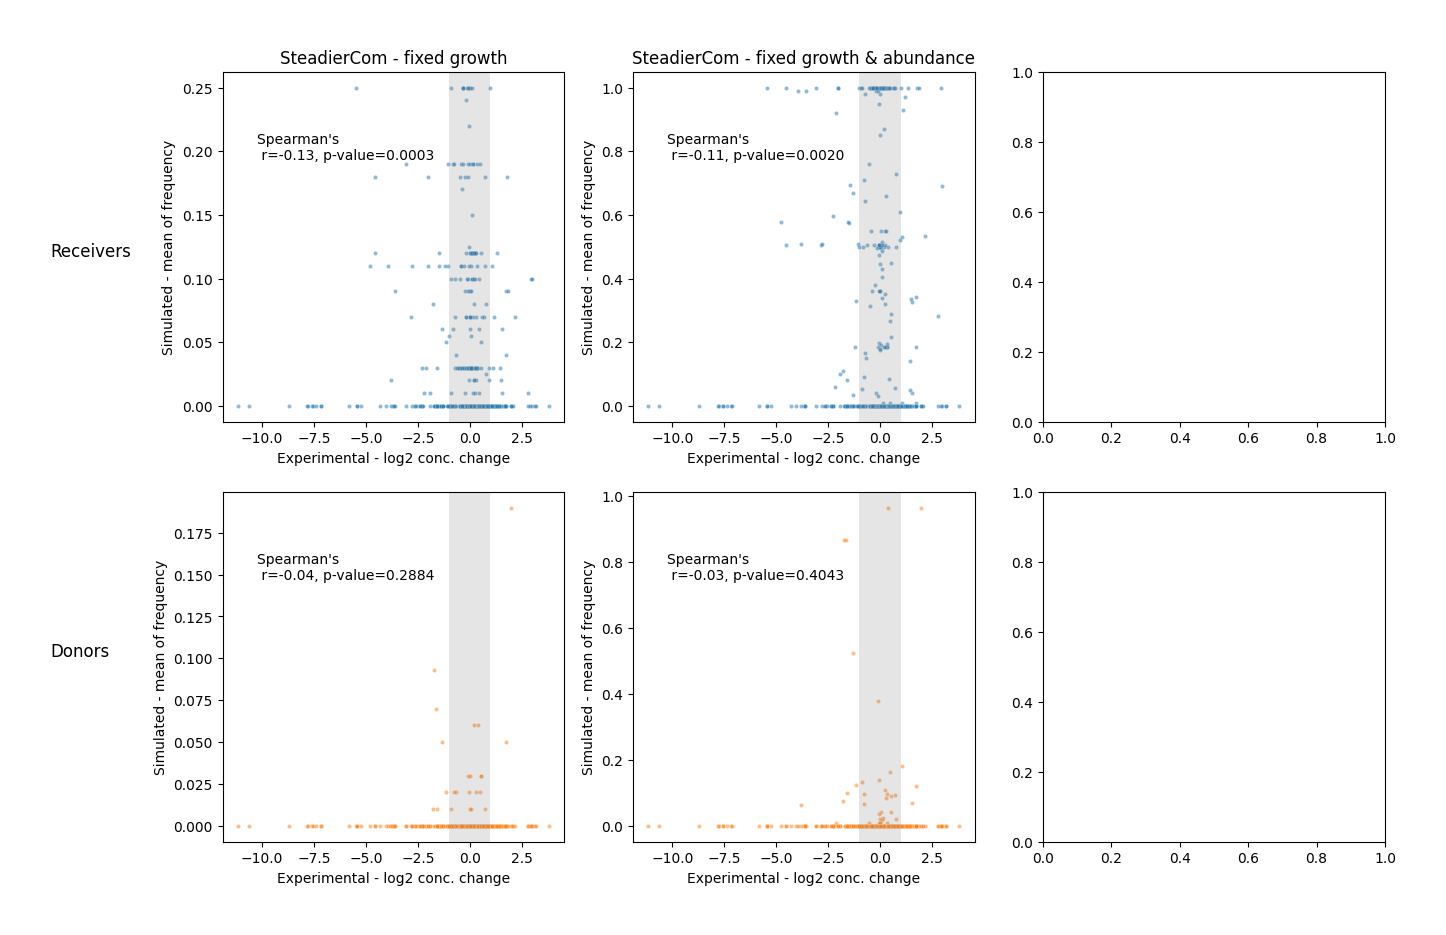

In [18]:
simulation_method="steadiercom"
receiver_or_donor="receiver"
agg_method ="mean"
metric = "frequency"
fig,axs = compare_exp_sim.plot_scatter_plots(simulation_dict,
                                             signal_exp,
                   simulation_method=simulation_method,
                   receiver_or_donor=receiver_or_donor,
                   agg_method=agg_method,
                   metric=metric)


#### Receivers - SteadierCom - scatterplot - rate

[INFO] plot_scatter_plots uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


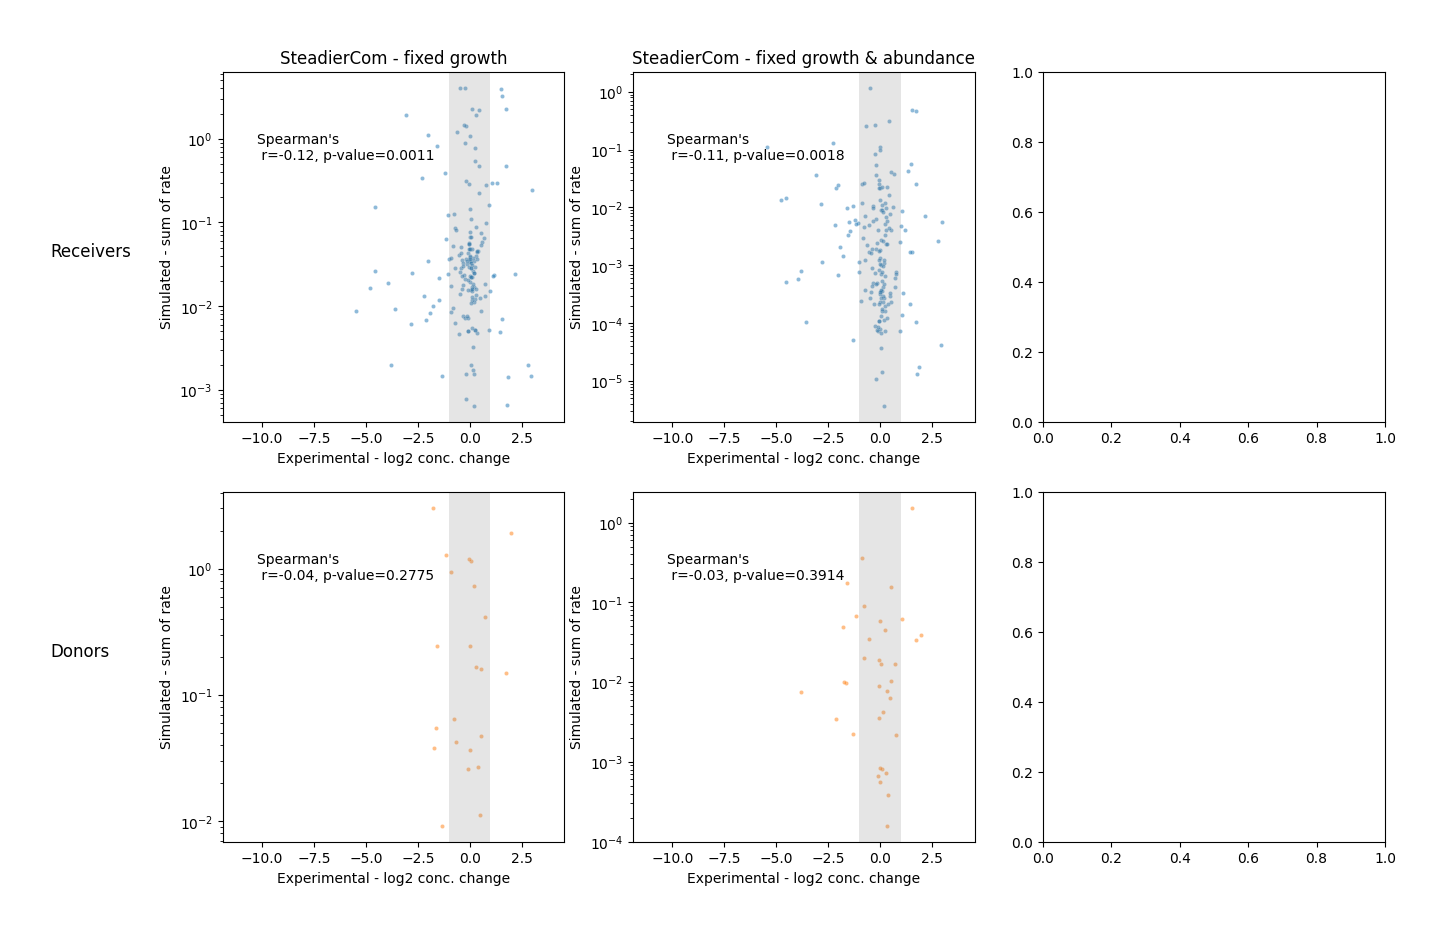

In [19]:
simulation_method="steadiercom"
receiver_or_donor="receiver"
agg_method ="sum"
metric = "rate"

fig,axs = compare_exp_sim.plot_scatter_plots(simulation_dict,
                                             signal_exp,
                   simulation_method=simulation_method,
                   receiver_or_donor=receiver_or_donor,
                   agg_method=agg_method,
                   metric=metric)

#### Receivers - SteadierCom - scatterplot - mass_rate

[INFO] plot_scatter_plots uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


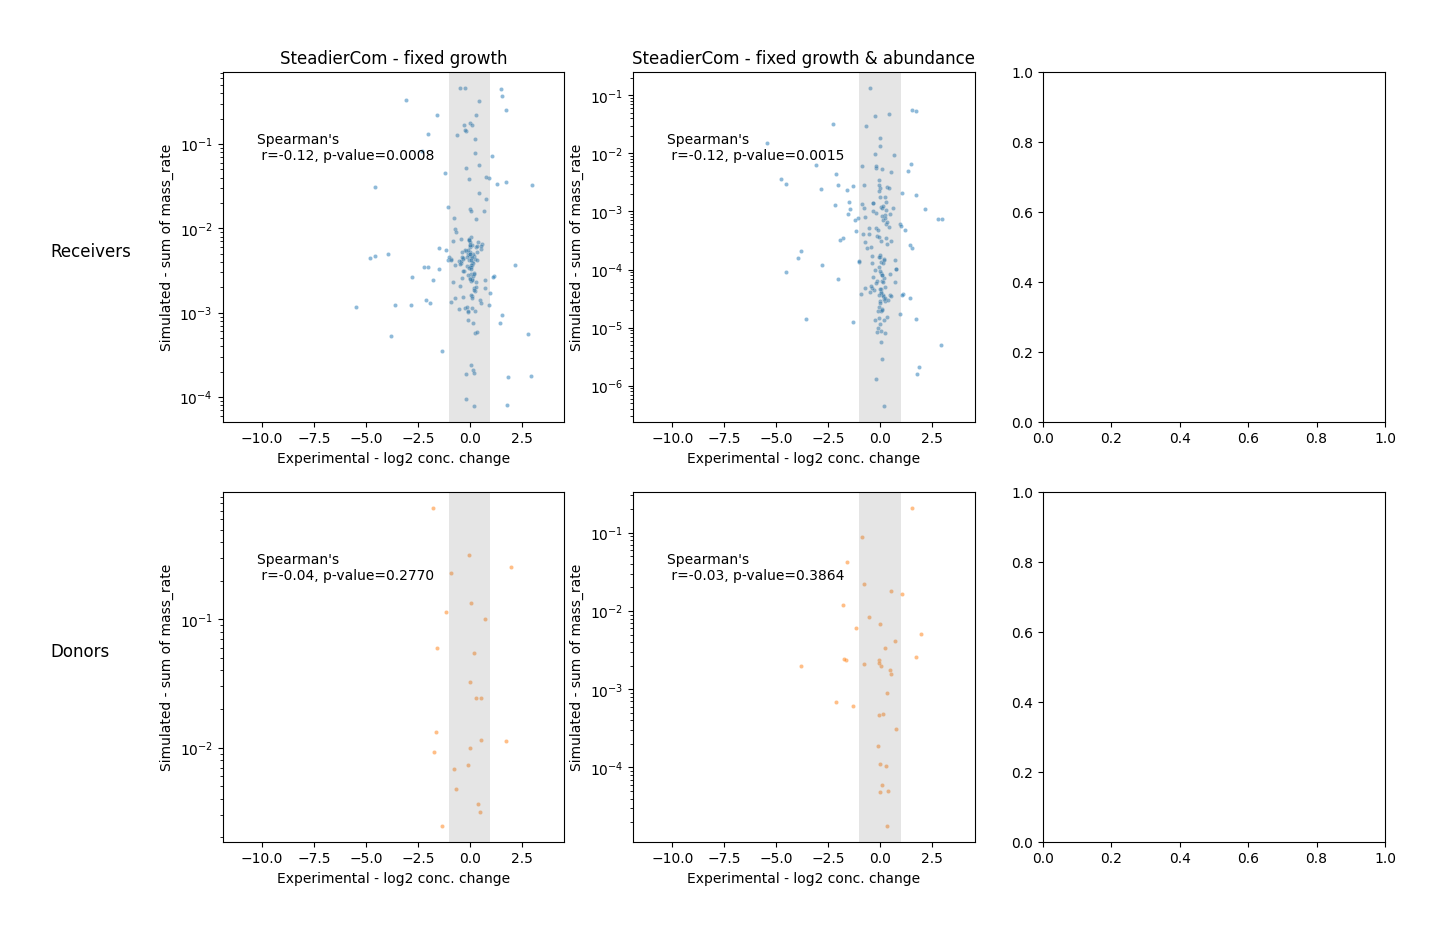

In [20]:
simulation_method="steadiercom"
receiver_or_donor="receiver"
agg_method ="sum"
metric = "mass_rate"

fig,axs = compare_exp_sim.plot_scatter_plots(simulation_dict,
                                             signal_exp,
                   simulation_method=simulation_method,
                   receiver_or_donor=receiver_or_donor,
                   agg_method=agg_method,
                   metric=metric)

# Binary system - comparison

## Evaluating changes in scores with changing thresholds

In [21]:
role_config = {
    "receiver": {"exp_cond": "< -1", "freq_thresh": 0.1,  "rate_thresh": 1e-4},
    "donor":    {"exp_cond": "> 1",   "freq_thresh": 0.01, "rate_thresh": 1e-5}
}

exp_sim_bool_dict = compare_exp_sim.run_all_evaluations(simulation_dict, signal_exp, role_config)


[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


In [22]:

all_results = {"rate":{},"freq":{}}
for exponent in np.linspace(0.0,6,13):
    sim_thresh = 10**(-exponent)
    role_config["receiver"]["freq_thresh"]=sim_thresh
    role_config["receiver"]["rate_thresh"]=sim_thresh
    
    exp_sim_bool_dict = compare_exp_sim.run_all_evaluations(simulation_dict, signal_exp, role_config)

    sim_bool_dict_rate_rec = compare_exp_sim.merge_eval_results(exp_sim_bool_dict, "receiver", ["steadiercom_rate", "steadycom_rate"])
    sim_bool_dict_freq_rec = compare_exp_sim.merge_eval_results(exp_sim_bool_dict, "receiver", ["steadiercom_frequency", "smetana"])

    scores_df_rate_rec = compare_exp_sim.score_dict_matches(sim_bool_dict_rate_rec)
    scores_df_freq_rec = compare_exp_sim.score_dict_matches(sim_bool_dict_freq_rec)
    
    scores_df_rate_rec.name=f"{sim_thresh}"
    scores_df_freq_rec.name=f"{sim_thresh}"
    all_results["rate"][sim_thresh]=scores_df_rate_rec
    all_results["freq"][sim_thresh] = scores_df_freq_rec

[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.

### Effect of threshold on rates on scores

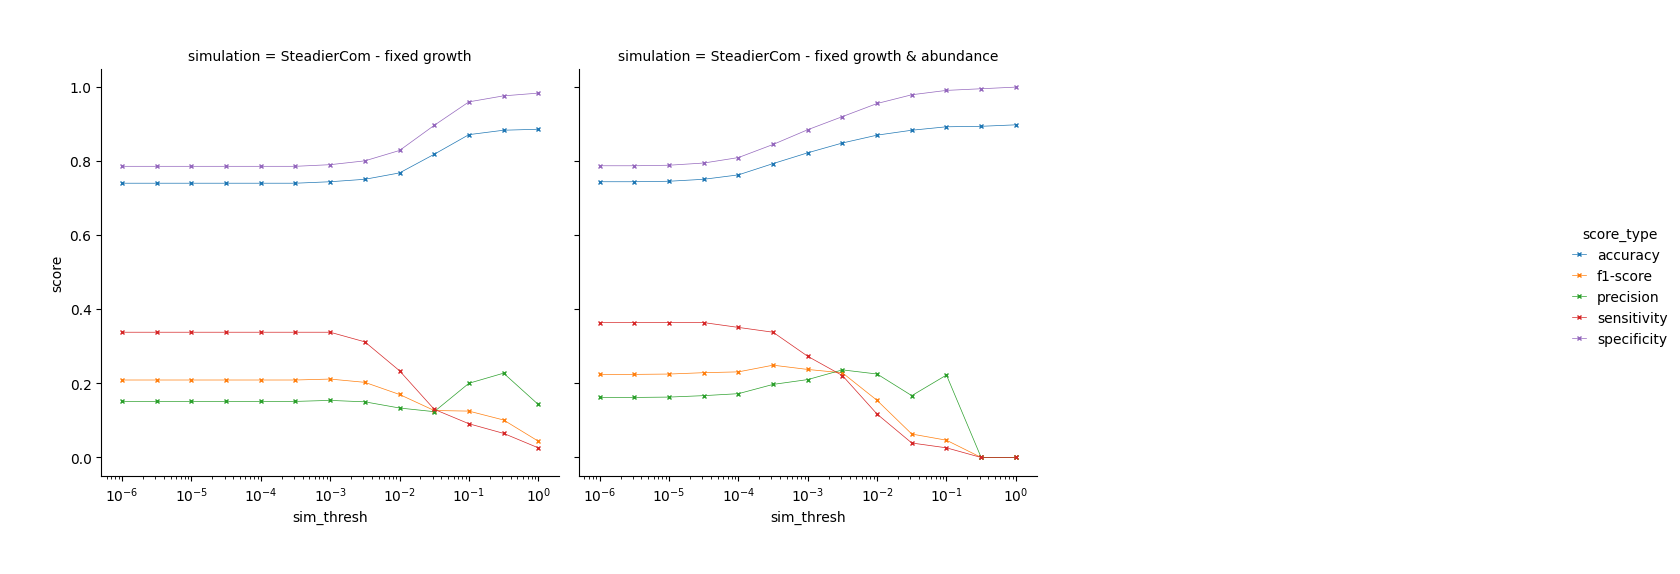

In [23]:
scores = pd.concat(all_results["rate"])

scores_df = scores.stack().reset_index()
scores_df.columns=["sim_thresh","score_type","simulation","score"]


plot = sns.relplot(scores_df,x="sim_thresh",y="score",hue="score_type",col="simulation",kind="line",marker="x",col_wrap=3)
for ax in plot.axes.flat:
    ax.set(xscale="log")
    for line in ax.lines:
        if line.get_marker() != 'None':
            color = line.get_color()
            line.set_markeredgecolor(color)
            line.set_markeredgewidth(1)
            


### Effect of threshold on frequency/mus on scores

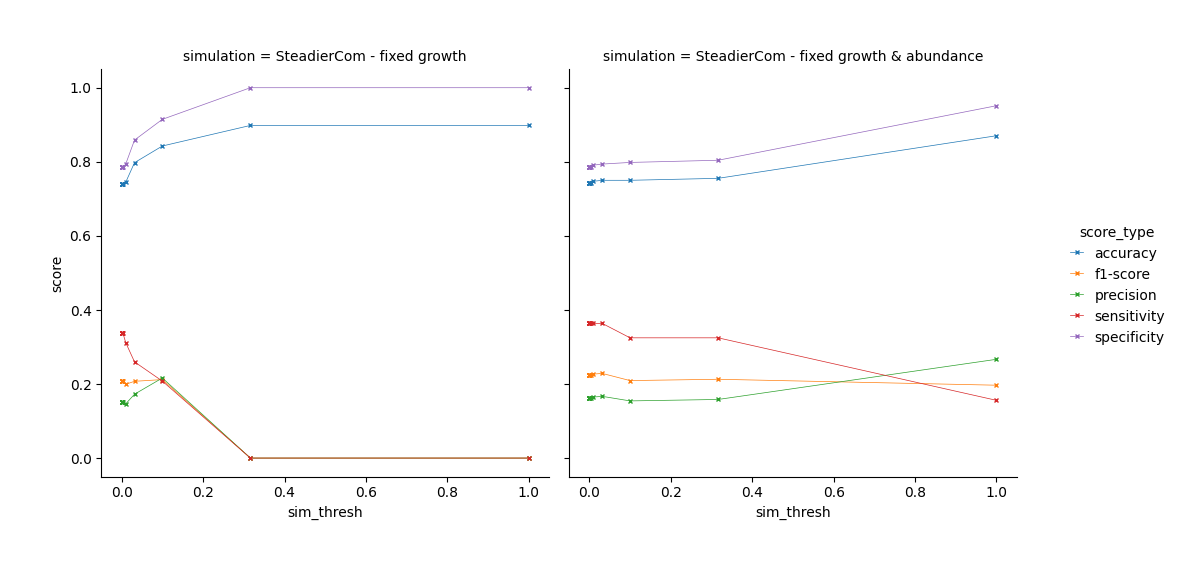

In [24]:
scores = pd.concat(all_results["freq"])

scores_df = scores.stack().reset_index()
scores_df.columns=["sim_thresh","score_type","simulation","score"]


plot = sns.relplot(scores_df,x="sim_thresh",y="score",hue="score_type",col="simulation",kind="line",marker="x",col_wrap=2)
for ax in plot.axes.flat:
    for line in ax.lines:
        if line.get_marker() != 'None':
            color = line.get_color()
            line.set_markeredgecolor(color)
            line.set_markeredgewidth(1)

## Precision-Recall curves

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


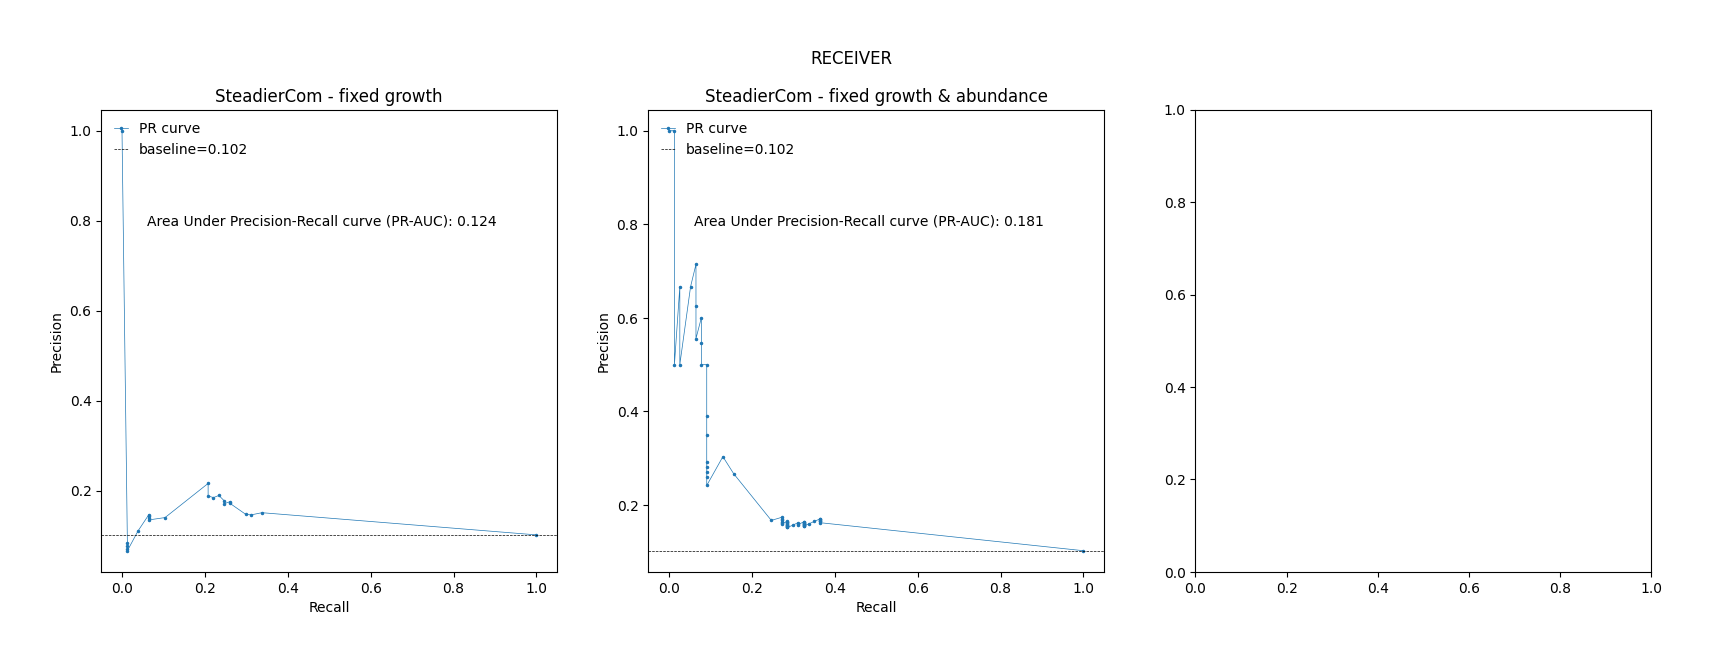

In [25]:
fig,axs = compare_exp_sim.plot_diagnostic_curve(simulation_dict,signal_exp,receiver_or_donor="receiver",simulation_method="steadiercom",metric="frequency",met_column="met_group",agg_method="sum")

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


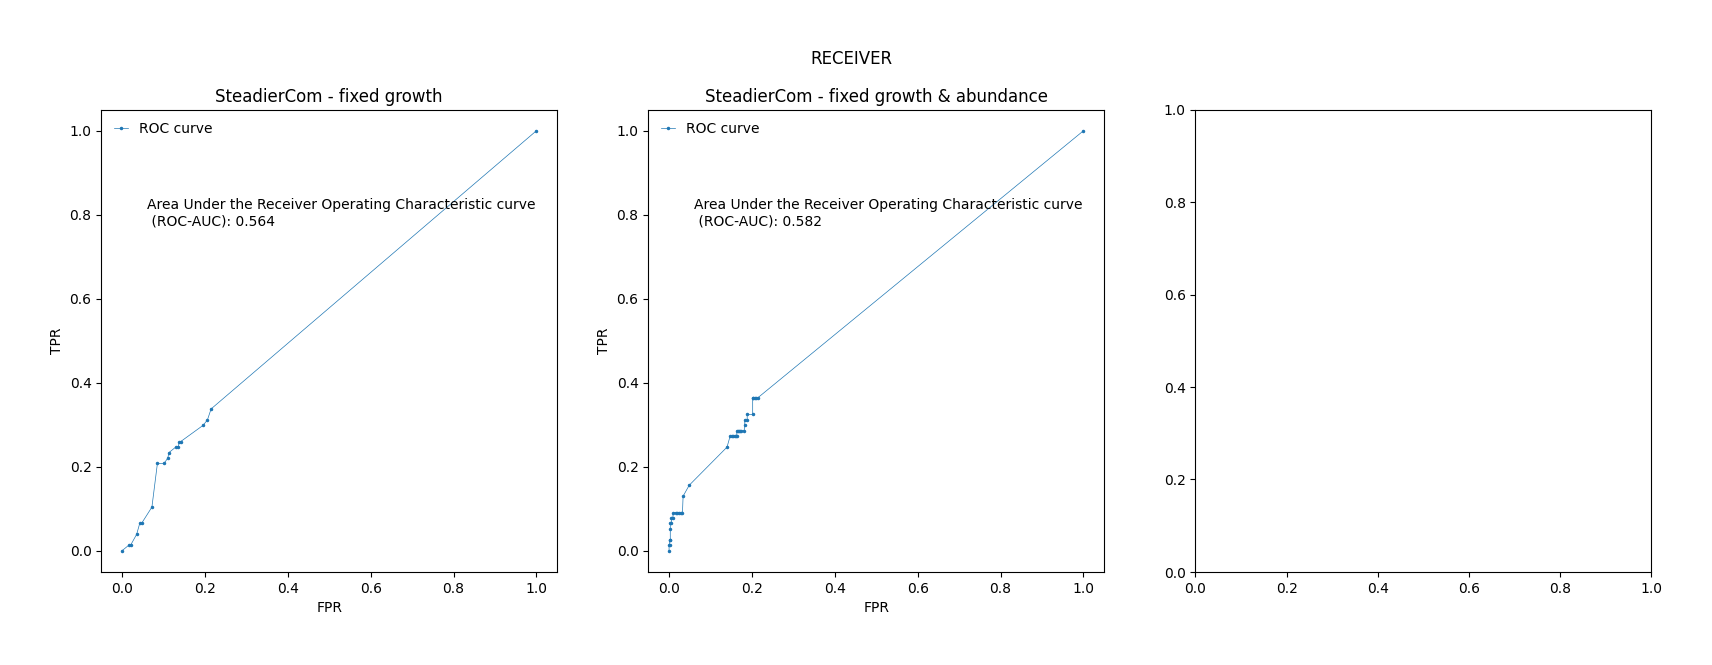

In [26]:
fig,axs = compare_exp_sim.plot_diagnostic_curve(simulation_dict,signal_exp,PR_or_ROC="ROC",receiver_or_donor="receiver",simulation_method="steadiercom",metric="frequency",met_column="met_group",agg_method="sum")

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


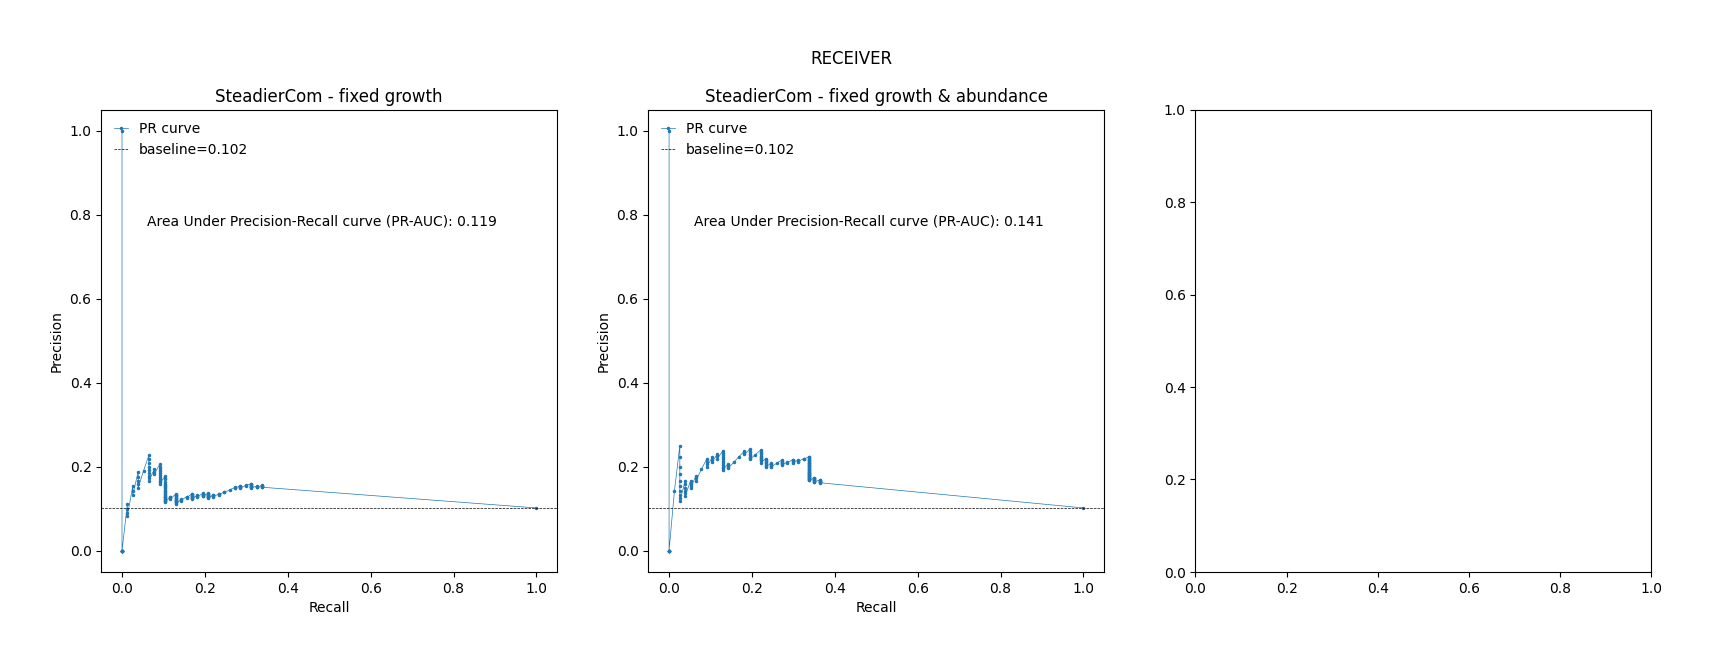

In [27]:
fig,axs =compare_exp_sim.plot_diagnostic_curve(simulation_dict,signal_exp,receiver_or_donor="receiver",simulation_method="steadiercom",metric="rate",met_column="met_group",agg_method="sum")

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


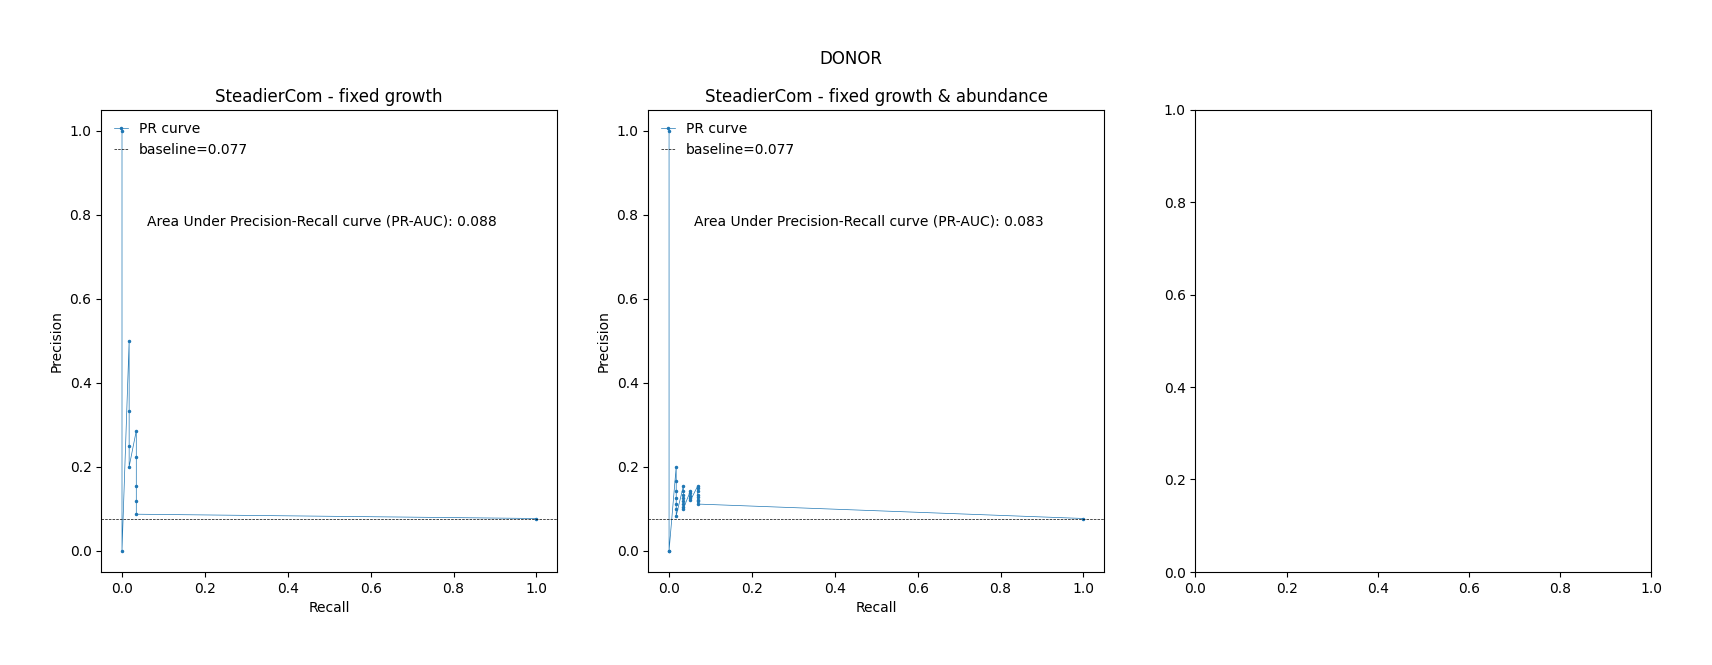

In [28]:
fig,axs = compare_exp_sim.plot_diagnostic_curve(simulation_dict,signal_exp,receiver_or_donor="donor",simulation_method="steadiercom",metric="frequency",met_column="met_group",agg_method="sum")


[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


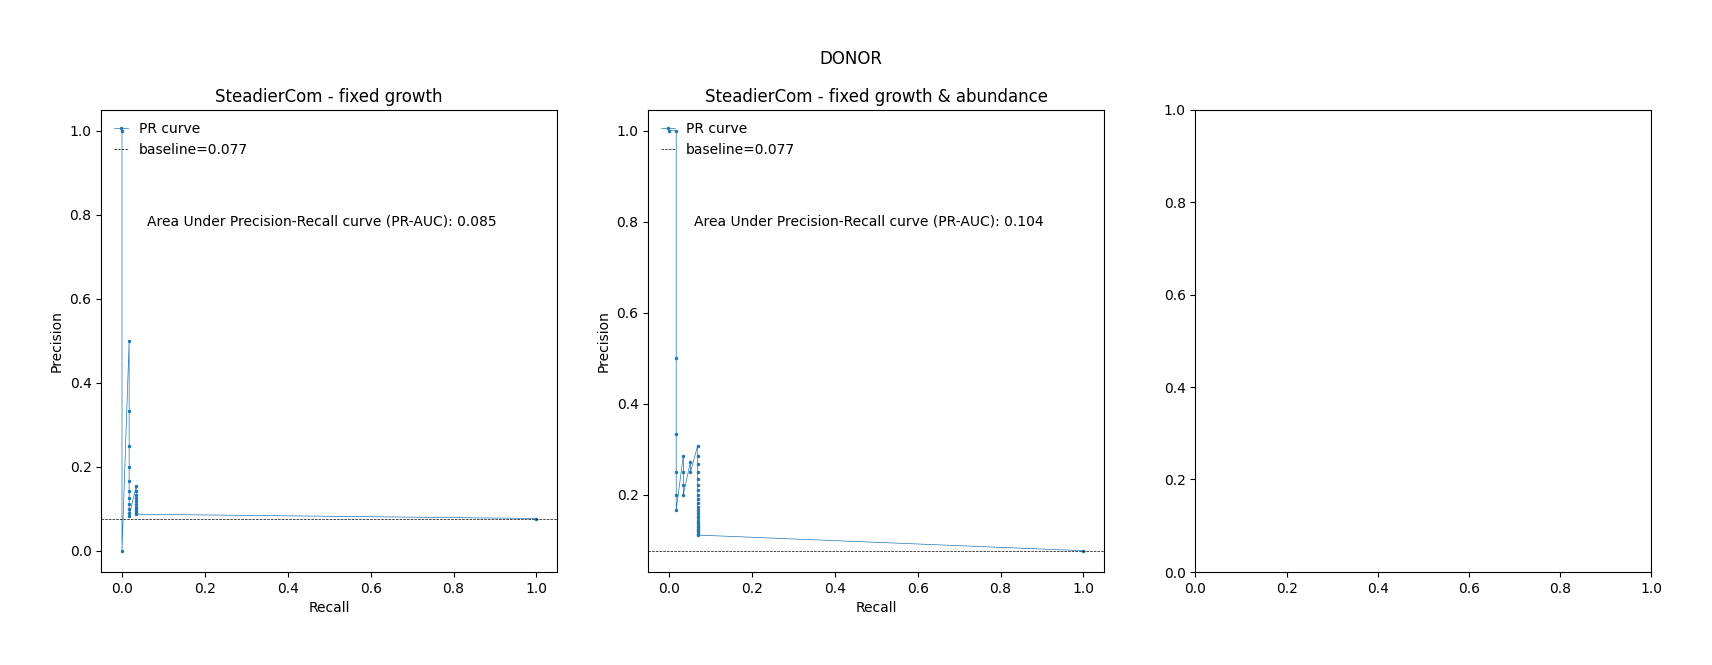

In [29]:
fig,axs = compare_exp_sim.plot_diagnostic_curve(simulation_dict,signal_exp,receiver_or_donor="donor",simulation_method="steadiercom",metric="rate",met_column="met_group",agg_method="sum")

### Direct interactions

In [30]:
def prepare_sim_met_venturelli(simulated_results,metid2group):
    
    """
    Function to create new column in simulation results with metabolite group "met_group" and to filter out results we are not interested in.
    """

    # Map met id to met group

    simulated_results = simulated_results[(simulated_results.donor!="environment") & (simulated_results.receiver!="environment")].copy()
    simulated_results = simulated_results[~simulated_results.donor.isna()].copy()
    simulated_results = simulated_results[~simulated_results.receiver.isna()].copy()
    simulated_results.donor = simulated_results.donor.map(lambda x: x.split("_")[0][0].upper()+x.split("_")[1][0].upper())
    simulated_results.receiver = simulated_results.receiver.map(lambda x: x.split("_")[0][0].upper()+x.split("_")[1][0].upper())

    
    simulated_res_reduced = simulated_results[simulated_results.compound.isin(metid2group.keys())].copy()
    simulated_res_reduced["met_group"] = simulated_res_reduced.compound.map(lambda x: metid2group[x])
    
    return simulated_res_reduced

def prepare_all_simulations_venturelli(sim_dicts, metid2group,verbose=True):
    """
    Function to prepare all simulation results for analysis with prepare_sim_met_venturelli.
    """
    
    simulation_dict = {}

    for method, sim_data in sim_dicts.items():
        simulation_dict[method] = {
            name: prepare_sim_met_venturelli(
                simulated_results=res,
                metid2group=metid2group,
            )
            for name, res in sim_data.items()
            }
    return simulation_dict

def prepare_exp_coop(dataset4,metname_groups,metname2group,threshold=1):
    
    signal_exp = compare_exp_sim.prepare_exp_met_venturelli(dataset4,metname_groups,metname2group)
    receivers_ds4 = (signal_exp<-threshold).rename_axis(["receiver","met_group"])
    donors_ds4 = (signal_exp>threshold).rename_axis(["donor","met_group"])

    receivers_ds4 = receivers_ds4.reset_index(name="value")
    donors_ds4 =donors_ds4.reset_index(name="value")

    merged = pd.merge(left=receivers_ds4,right=donors_ds4,on="met_group")
    merged["value"] = (merged["value_x"]*merged["value_y"]).map(int)
    merged.drop(columns=["value_x","value_y"])

    exp_signal_coop = merged.set_index(["receiver","donor","met_group"])["value"]
    return exp_signal_coop

from sklearn.metrics import confusion_matrix,recall_score,precision_score,classification_report,average_precision_score, roc_auc_score,precision_recall_curve,roc_curve

def plot_diagnostic_curve(simulation_dict,exp_signal,PR_or_ROC="PR",simulation_method="steadiercom",metric="frequency",met_column="met_group",agg_method="sum",verbose=True):
    fig,axs =  plt.subplots(1,3,figsize=(20, 6))
    
    i=0
    for name,sim_df in simulation_dict[simulation_method].items():
        sim_signal =sim_df.groupby(["receiver","donor",met_column]).sum()[metric]

        sim_signal = sim_signal.reindex(exp_signal.index,fill_value=0)

        y_true=exp_signal.values
        y_scores=sim_signal.values

        ax=axs[i]
        if PR_or_ROC=="PR":
            baseline = sum(y_true)/len(y_true)
            auc = average_precision_score(y_true, y_scores)
            precision, recall, thresholds = precision_recall_curve(y_true, y_scores)
            # Plot the curve

            ax.plot(recall, precision, marker='.', label='PR curve')
            ax.set_xlabel('Recall')
            ax.set_ylabel('Precision')
            plt.text(.1, .75, f"Area Under Precision-Recall curve (PR-AUC): {auc:.3f}",transform=ax.transAxes)

            ax.axhline(y=baseline, color='black', linestyle='--',label=f"baseline={baseline:.3f}")
        elif PR_or_ROC=="ROC":
            auc = roc_auc_score(y_true, y_scores)
            fpr, tpr, thresholds = roc_curve(y_true, y_scores)
            # Plot the curve

            ax.plot(fpr, tpr, marker='.', label='ROC curve')
            ax.set_xlabel('FPR')
            ax.set_ylabel('TPR')

            plt.text(.1, .75, f"Area Under the Receiver Operating Characteristic curve \n (ROC-AUC): {auc:.3f}",transform=ax.transAxes)

        ax.set_title(f"{name}")
        ax.legend()

        i+=1
    return fig,axs

In [31]:
simulation_dict_new = prepare_all_simulations_venturelli(simulation_sources,metid2group)

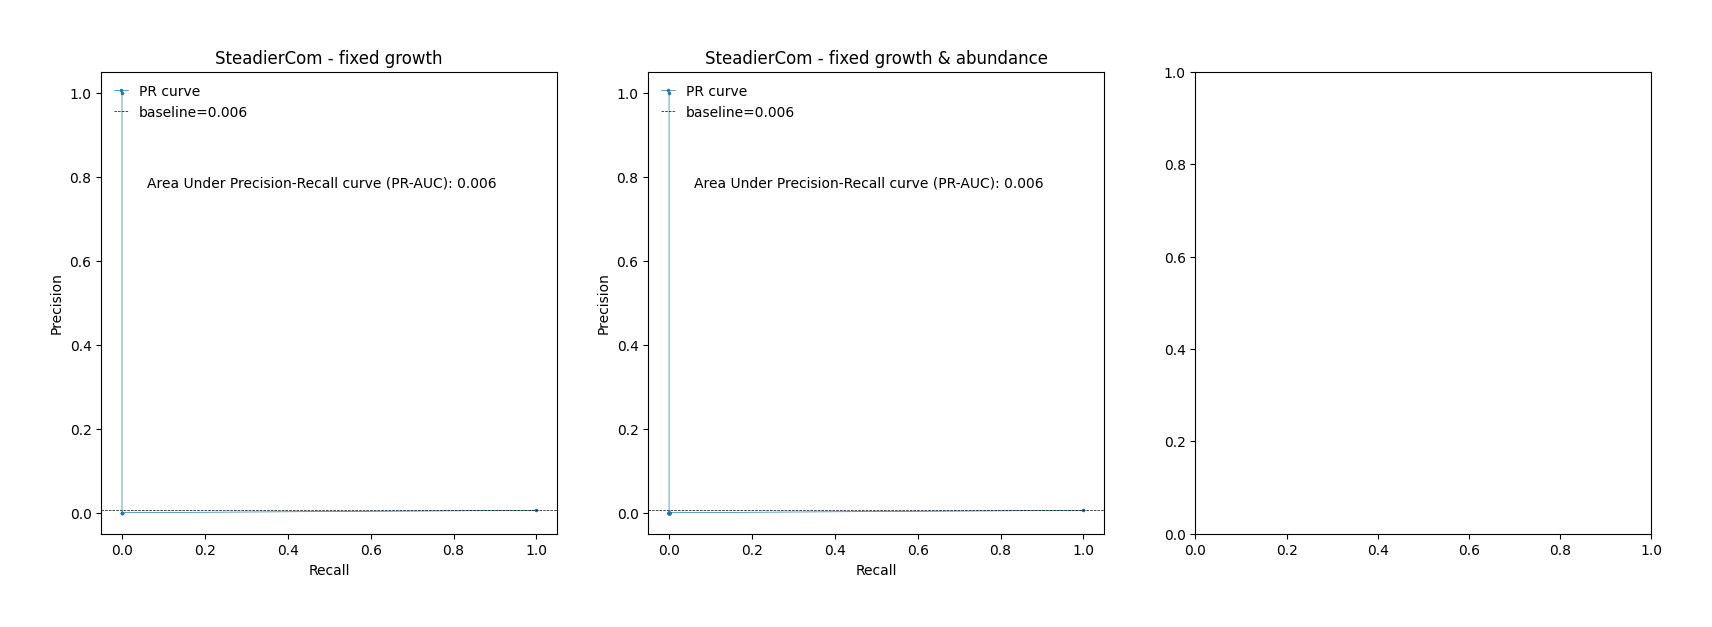

In [32]:
exp_signal_coop= prepare_exp_coop(dataset4,metname_groups,metname2group,threshold=1)

fig,axs = plot_diagnostic_curve(simulation_dict_new,exp_signal_coop,metric="frequency")
plt.savefig("don_met_rec_steadiercom_1.png")

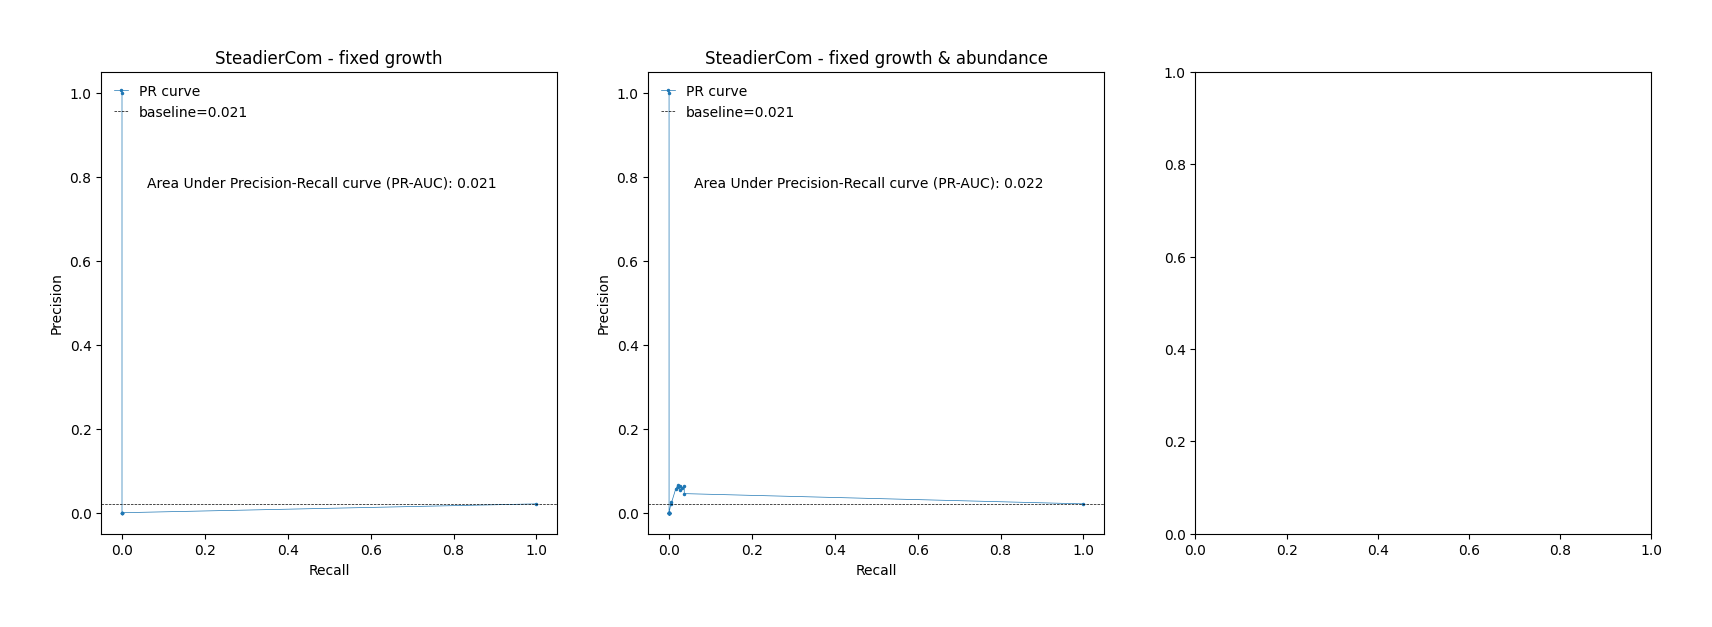

In [33]:
exp_signal_coop= prepare_exp_coop(dataset4,metname_groups,metname2group,threshold=0.5)

fig,axs = plot_diagnostic_curve(simulation_dict_new,exp_signal_coop)
plt.savefig("don_met_rec_steadiercom_05.png")

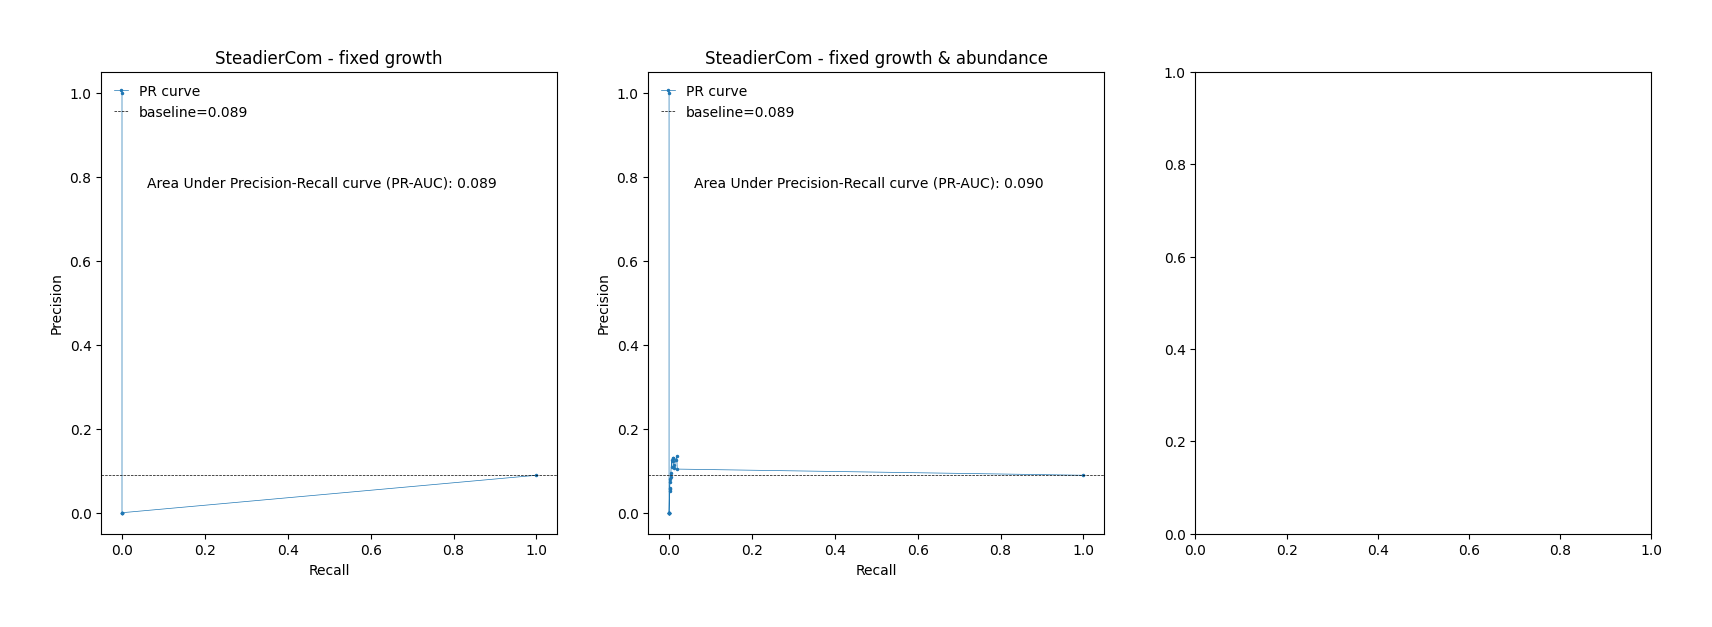

In [34]:
exp_signal_coop= prepare_exp_coop(dataset4,metname_groups,metname2group,threshold=0.1)

fig,axs = plot_diagnostic_curve(simulation_dict_new,exp_signal_coop)
plt.savefig("don_met_rec_steadiercom_01.png")